# 15 · Alpha 融合：把 A–E 变成连续因子，再合成一个 spread 预测

单个 idea 都太弱（D-019、D-022、D-025–D-028）。这里换一个角度：把每个 idea 抽象成**连续的 alpha 因子**，统一预测**同一个目标**——主力对（最近两张可交易合约）未来的 spread 收益，再把多个因子合成一个预测，最后用 v2 回测框架变现。协议见 D-030。

- **样本**：train 1986–2005（筛因子、拟合模型），validation 2006–2015（选模型、horizon、组合规则），test 2016–2026 只读一次。
- **全部是时序统计**：每个商品的因子只和它自己未来的 spread 收益比；截面组合只作为对照实验（各交易所 settle 时间不同）。
- **时点**：t 的 settle 出信号，t+1 成交；`[t, t+1]` 是论文时点，只作诊断。
- **计算**放在 `scripts/run_alpha.py`（`--stage select` / `--stage test`），本 notebook 只读结果、画图。

In [1]:
import json
import os
import pickle
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

In [2]:
import numpy as np
import pandas as pd
from IPython.display import display

from src import alpha_factors as af, alpha_figures as AF, alpha_models as M, alpha_portfolio as P, alpha_screen as S
from src import config, figures as F, horizon, plotstyle as ps, report

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
print("LaTeX text rendering:", ps.use())

OUT = config.OUTPUT_DIR / "alpha"
SEL = json.loads((OUT / "selection.json").read_text())
FACTORS = list(af.FACTORS)
BLOCK = SEL["block"]
ROOT_ORDER = ["CL", "CO", "HO", "XB", "NG", "C", "W", "S", "SM", "BO", "O", "RR",
              "SB", "KC", "CC", "CT", "JO", "LB", "LC", "FC", "LH", "GC", "SI", "HG"]

LaTeX text rendering: True


## 1. 十二个因子

每个 idea 抽象成 2–3 个连续分数，全部只用 t 及以前的 settle。符号保持原定义（例如 carry 为正 = backwardation），方向由模型在 train 上学，不再人为 flip。

| Idea | 因子 | 定义 |
|---|---|---|
| A carry | `a_carry`, `a_carry_dev` | 主力对年化 carry；减去自身 252 天均值 |
| B 曲线形状 | `b_curve_carry`, `b_rel_carry` | 前段减后段相邻 carry；主力对 carry 减相邻 carry 均值 |
| C 均值回复 | `c_z20`, `c_z60`, `c_rev5` | 连续 spread 指数的 −z（20/60 天）；−过去 5 天 spread 收益 |
| D 曲线动量 | `d_mom21`, `d_mom63`, `d_mom252` | 主力对过去 21/63/252 天累计 spread 收益 |
| E Nelson–Siegel | `e_dslope`, `e_dcurv` | NS slope / curvature 的一日变化 ÷ 价格水平 |

下图：因子之间的相关性（train，pooled）。同一 idea 内部高度相关，跨 idea 大多很低——这正是融合的价值所在。

In [3]:
panel = pd.read_parquet(OUT / "panel_select.parquet")
usable = panel.loc[panel["usable"]]
train = S.slice_period(usable, "train")
valid = S.slice_period(usable, "valid")
display(train[FACTORS].describe().T[["count", "mean", "std", "min", "max"]].round(4))

,count,mean,std,min,max
a_carry,88385.0,-0.0222,0.2678,-2.9896,4.0682
a_carry_dev,87342.0,-0.0015,0.2397,-2.0590,4.1653
b_curve_carry,88307.0,-0.0223,0.3004,-6.0271,3.8314
b_rel_carry,88385.0,-0.0121,0.1561,-2.8020,2.4220
c_z20,88050.0,0.1046,1.2817,-4.2485,4.2485
c_z60,87838.0,0.1407,1.3992,-7.5636,7.5688
c_rev5,88385.0,0.0001,0.0103,-0.2770,0.2486
d_mom21,88289.0,-0.0002,0.0192,-0.2887,0.2410
d_mom63,88010.0,-0.0008,0.0326,-0.3067,0.2922
d_mom252,86616.0,-0.0037,0.0715,-0.5204,0.3901


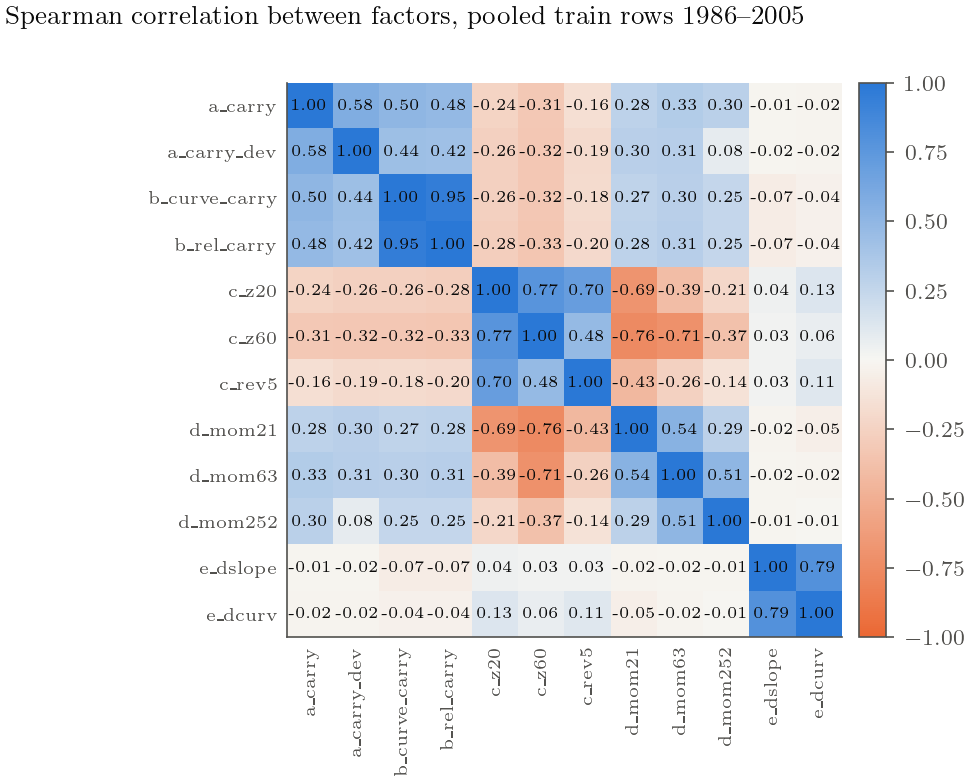

In [4]:
fig = AF.factor_correlation(train, FACTORS)
ps.save(fig, "alpha_factor_corr");

## 2. Day-block bootstrap：block 取多长

每个商品的 IC 在日期上自相关（因子持续、前向收益窗口重叠），普通 bootstrap 会低估标准误。做法：在**共同日历**上按 block 重抽日期，所有商品、所有因子共用同一组日期——这样跨商品平均 IC 的标准误也有效。

实验：block = 1, 5, 10, 21, 42, 63, 126 天。均值 IC 不随 block 变（重抽不改变估计量），**标准误先升后平**；取第一个落在平台（与 126 天的 SE 相差 10% 以内）的 block。

In [5]:
sens = pd.read_parquet(OUT / "block_sensitivity.parquet")
display(sens.loc[sens["root"].eq("ALL")].pivot(index="score", columns="block", values="se").round(4))
print("chosen block:", BLOCK, "days; at horizon h the block is max(block, h)")

block,1,5,10,21,42,63,126
score,,,,,,,
a_carry,0.0039,0.0067,0.0075,0.0075,0.0079,0.0081,0.0087
a_carry_dev,0.0040,0.0067,0.0075,0.0072,0.0072,0.0070,0.0071
b_curve_carry,0.0041,0.0066,0.0071,0.0077,0.0075,0.0075,0.0072
b_rel_carry,0.0040,0.0065,0.0071,0.0077,0.0074,0.0073,0.0070
c_rev5,0.0040,0.0059,0.0062,0.0064,0.0068,0.0066,0.0072
c_z20,0.0036,0.0059,0.0065,0.0069,0.0068,0.0065,0.0066
c_z60,0.0037,0.0060,0.0068,0.0070,0.0072,0.0068,0.0073
d_mom21,0.0038,0.0062,0.0072,0.0073,0.0070,0.0068,0.0071
d_mom252,0.0039,0.0066,0.0071,0.0070,0.0071,0.0071,0.0072


chosen block: 10 days; at horizon h the block is max(block, h)


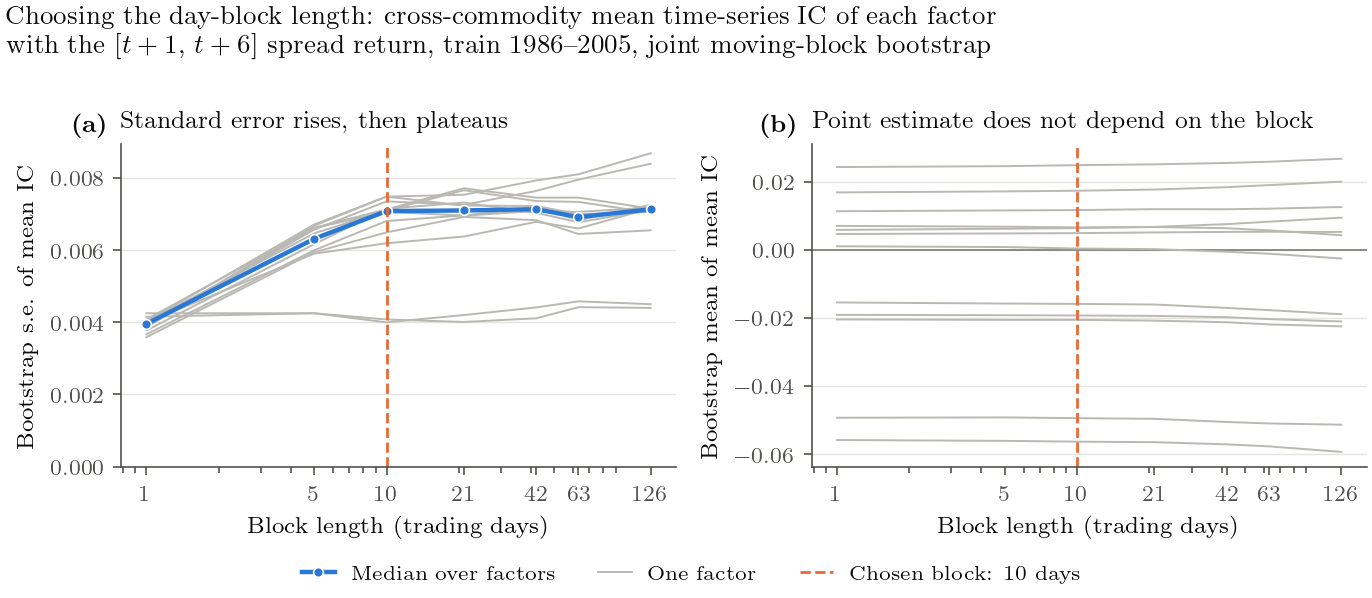

In [6]:
fig = AF.block_sensitivity(sens, BLOCK)
ps.save(fig, "alpha_block_length");

## 3. 因子筛选（train，每个 horizon 分别筛）

规则（预先登记）：在 ≥ 一半商品上显著（bootstrap p<0.05，且方向与跨商品均值一致）→ 通过；若通过的少于 3 个，再放宽为“跨商品均值 IC 的 95% CI 不含 0，且 ≥ 2/3 商品同号”。

In [7]:
screen = pd.read_parquet(OUT / "screen.parquet")
display(screen.pivot(index="score", columns="target", values="rule").reindex(FACTORS)[af.TARGETS])
for t in af.TARGETS:
    print(f"{t:9s}", SEL["features"][t])

target,fwd_0_1,fwd_1_2,fwd_1_3,fwd_1_6,fwd_1_11,fwd_1_22
score,,,,,,
a_carry,primary,fallback,fallback,fallback,fallback,fallback
a_carry_dev,primary,fallback,fallback,primary,primary,primary
b_curve_carry,,,,,fallback,fallback
b_rel_carry,primary,,,,fallback,fallback
c_z20,primary,fallback,fallback,fallback,fallback,fallback
c_z60,,,,,,
c_rev5,primary,fallback,fallback,fallback,fallback,fallback
d_mom21,,,,,,
d_mom63,,,,,,


fwd_0_1   ['a_carry', 'a_carry_dev', 'b_rel_carry', 'c_z20', 'c_rev5']
fwd_1_2   ['a_carry', 'a_carry_dev', 'c_z20', 'c_rev5']
fwd_1_3   ['a_carry', 'a_carry_dev', 'c_z20', 'c_rev5', 'e_dcurv']
fwd_1_6   ['a_carry', 'a_carry_dev', 'c_z20', 'c_rev5', 'e_dcurv']
fwd_1_11  ['a_carry', 'a_carry_dev', 'b_curve_carry', 'b_rel_carry', 'c_z20', 'c_rev5']
fwd_1_22  ['a_carry', 'a_carry_dev', 'b_curve_carry', 'b_rel_carry', 'c_z20', 'c_rev5']


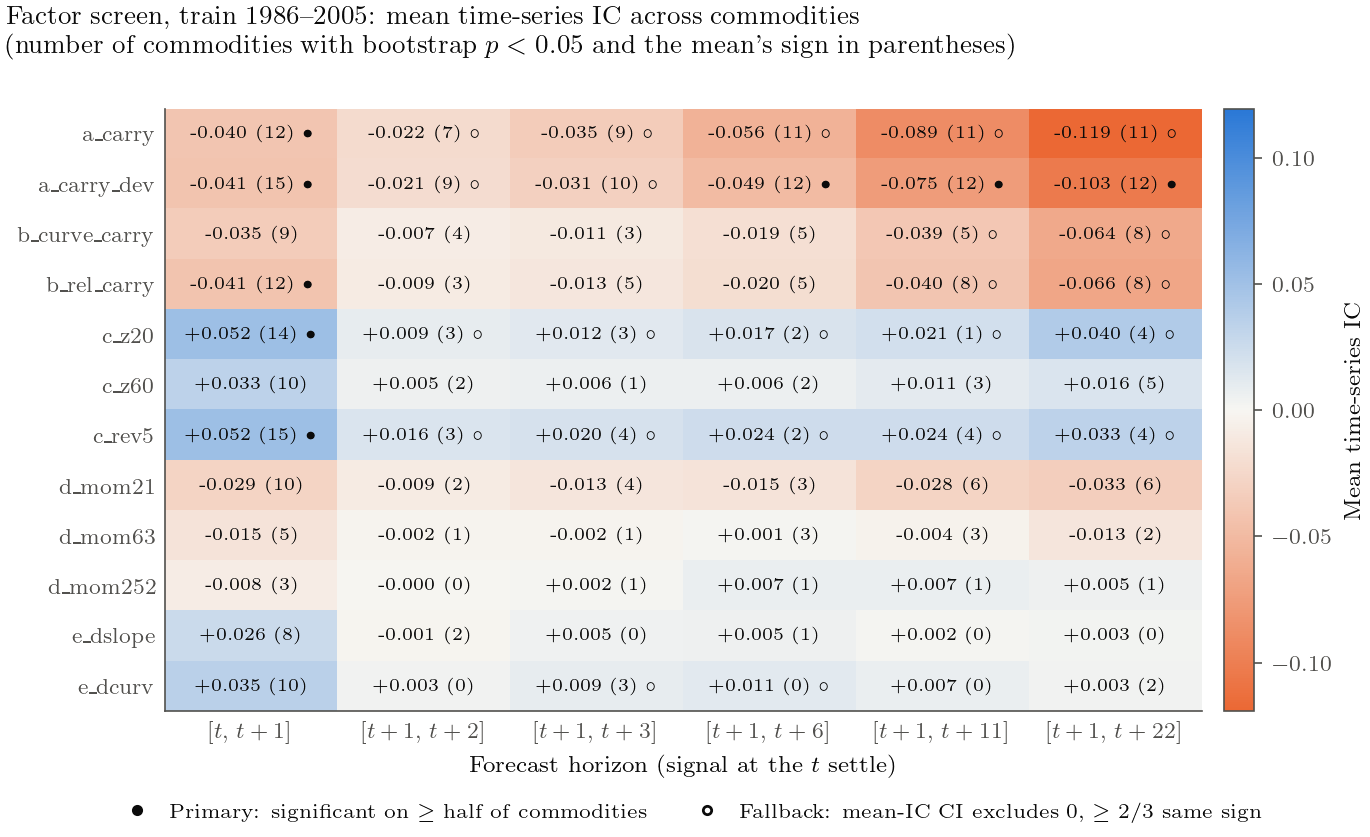

In [8]:
fig = AF.screen_heatmap(screen, FACTORS)
ps.save(fig, "alpha_screen");

最强因子在每个商品上的 IC 分布：`a_carry_dev` 对 `[t+1, t+6]`，每个商品一个竖直直方图，标出 bootstrap p 值。

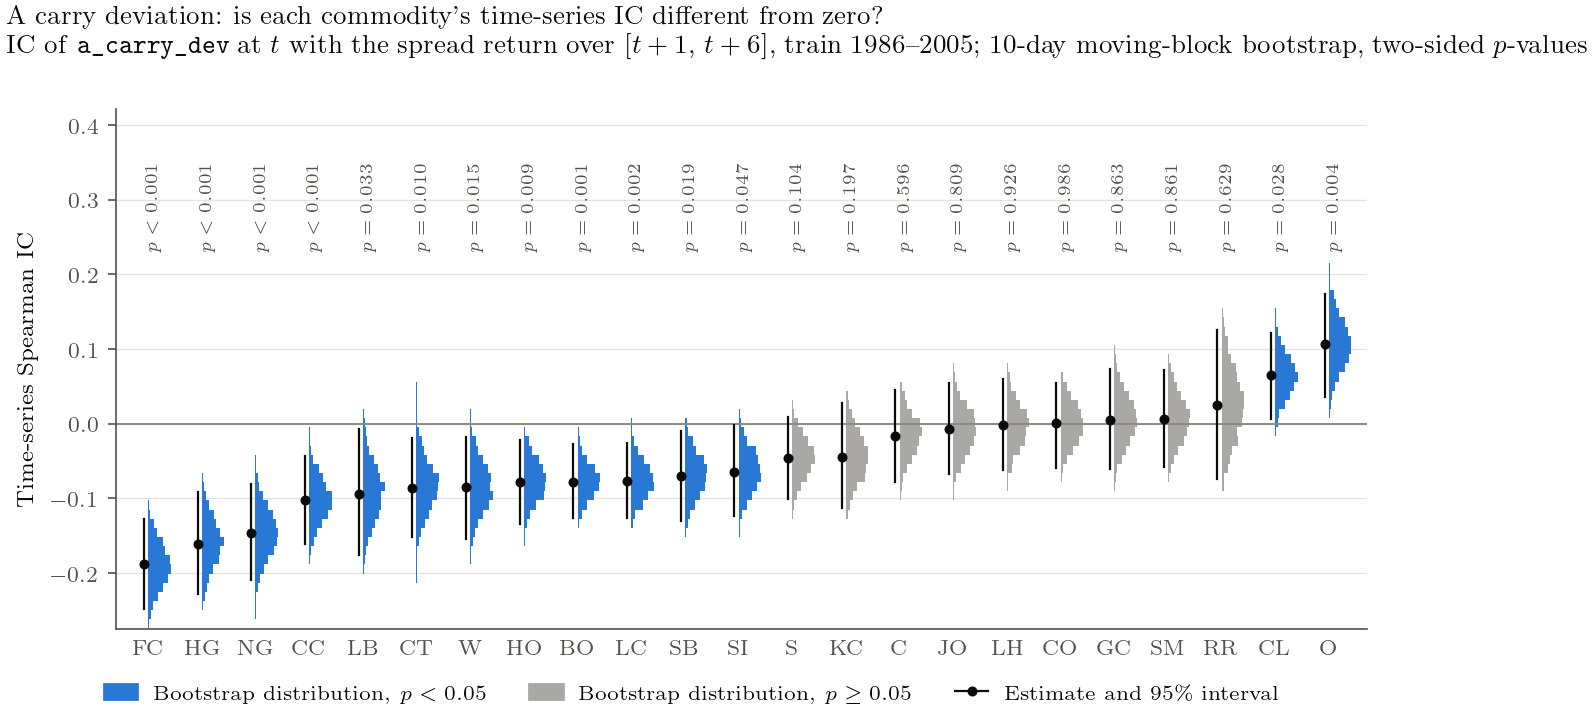

In [9]:
tgt = "fwd_1_6"
mats = S.rank_matrices(train, ["a_carry_dev"], tgt)
boot = S.joint_bootstrap(mats, ["a_carry_dev"], max(BLOCK, 5), n_boot=2000)
tab = S.ic_table(mats, boot, "a_carry_dev")
per = tab.loc[tab["root"].ne("ALL")]
draws = {r: boot["a_carry_dev"][1][:, i] for i, r in enumerate(mats["roots"]) if r in set(per["root"])}
fig = F.bootstrap_ic_distribution(per, draws, "A carry deviation", r"\texttt{a\_carry\_dev}",
                                  r"$[t+1,\,t+6]$, train 1986--2005", max(BLOCK, 5))
ps.save(fig, "alpha_root_ic_a_carry_dev");

## 4. 模型：OLS / Ridge / Lasso / ElasticNet / RF / XGBoost

所有商品 pooled 一起拟合；特征是因果缩放后的因子（缺失 → 0），目标是 ÷（滞后 60 天 spread 波动 × √窗口长度）后的前向 spread 收益。超参数固定，只给 Ridge、Lasso 各两档——调参不是重点。

模型在 train 上拟合，在 validation 上比较：指标是**预测与实现 spread 收益的跨商品平均时序 IC**。

In [10]:
msum = pd.read_parquet(OUT / "model_summary.parquet")
mpairs = pd.read_parquet(OUT / "model_pairs.parquet")
with open(OUT / "model_draws.pkl", "rb") as fh:
    mdraws = pickle.load(fh)
display(msum.pivot(index="model", columns="target", values="mean_ic").reindex(list(M.MODEL_ZOO))[af.TARGETS].round(4))
display(msum.pivot(index="model", columns="target", values="wins").reindex(list(M.MODEL_ZOO))[af.TARGETS])
print("selected:", SEL["models"])

target,fwd_0_1,fwd_1_2,fwd_1_3,fwd_1_6,fwd_1_11,fwd_1_22
model,,,,,,
ols,0.0176,0.0357,0.0448,0.0673,0.0955,0.1184
ridge_1e3,0.0177,0.0358,0.0451,0.0676,0.0961,0.1176
ridge_1e5,0.0208,0.0350,0.0497,0.0718,0.0855,0.1077
lasso_1e-3,0.0176,0.0362,0.0458,0.0682,0.0953,0.1178
lasso_1e-2,0.0163,0.0316,0.0449,0.0694,0.0805,0.1239
enet,0.0173,0.0325,0.0490,0.0711,0.0940,0.1199
rf,0.0250,0.0239,0.0247,0.0617,0.0822,0.1124
xgb,0.0205,0.0144,0.0173,0.0497,0.0860,0.1161


target,fwd_0_1,fwd_1_2,fwd_1_3,fwd_1_6,fwd_1_11,fwd_1_22
model,,,,,,
ols,1,2,2,1,1,1
ridge_1e3,2,2,3,2,1,1
ridge_1e5,5,2,2,1,0,0
lasso_1e-3,1,2,4,3,1,1
lasso_1e-2,0,1,2,1,0,5
enet,1,1,4,1,1,3
rf,5,1,1,1,0,0
xgb,0,0,0,0,0,0


selected: {'fwd_0_1': 'ridge_1e5', 'fwd_1_2': 'ols', 'fwd_1_3': 'lasso_1e-3', 'fwd_1_6': 'lasso_1e-3', 'fwd_1_11': 'ols', 'fwd_1_22': 'lasso_1e-2'}


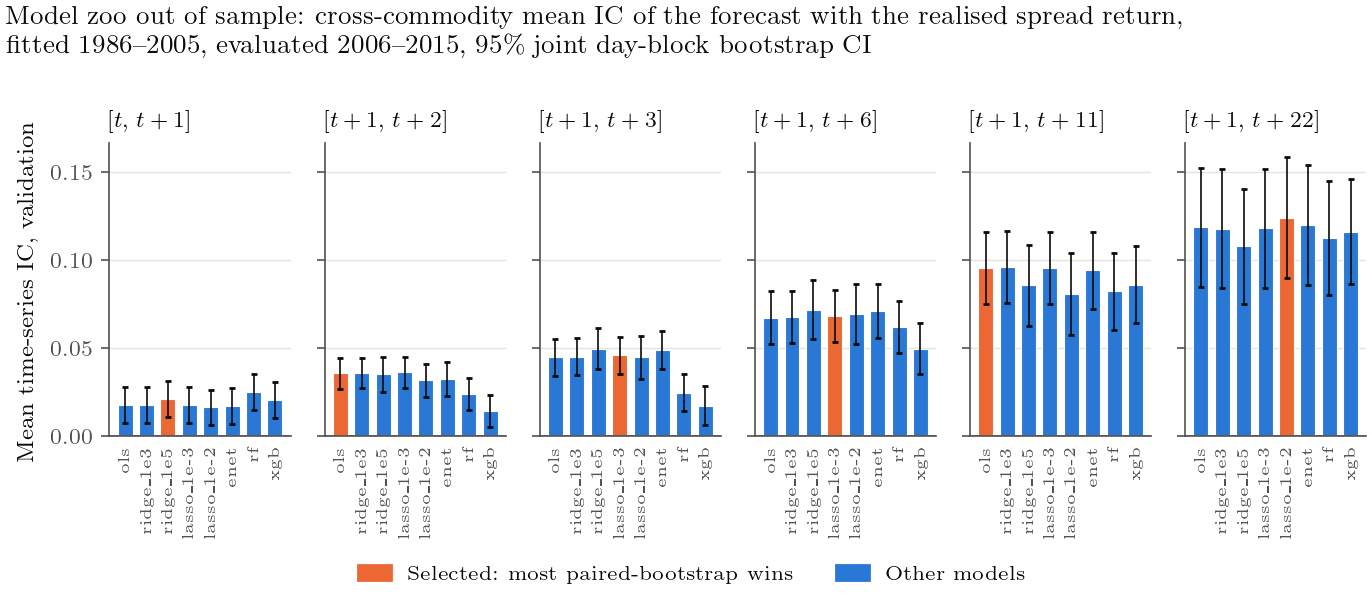

In [11]:
fig = AF.model_ic_by_horizon(msum, SEL["models"])
ps.save(fig, "alpha_model_ic");

### IC 为什么随 horizon 上升？什么时候到顶？

信号是慢变量（carry 一天几乎不变），噪声是快变量：h 天里预期收益 ∝ h，噪声 ∝ √h，所以 IC ≈ (μ/σ)·√h 会随 horizon 上升，直到信号衰减。但窗口越长，独立观测越少（每年约 252/h 个），所以要比较的是**年化 IC = IC × √(252/h)**（fundamental law）。

为了看到 252 天，这里改用 **rolled** 收益：一直持有当前主力对、在 roll 日换到新主力对（fixed-pair 收益在长窗口里因为近月到期而大量缺失，22 天就少了约 25% 的行，而且只剩远离到期的日子）。下表和下图只用 2015 年以前的数据。

In [12]:
term = pd.read_parquet(OUT / "ic_term_structure.parquet")
TERM_LABELS = {"pred_fwd_1_6": r"Forecast fitted for $[t+1,\,t+6]$", "pred_fwd_1_22": r"Forecast fitted for $[t+1,\,t+22]$",
               "a_carry": "a_carry", "b_rel_carry": "b_rel_carry", "c_rev5": "c_rev5", "d_mom252": "d_mom252"}
for per in ("train", "valid"):
    print(per)
    display(term.loc[term["period"].eq(per)].pivot(index="h", columns="score", values=["ic", "ic_ann"]).round(3))

train


ic                                                         ic_ann                                                       
score a_carry b_rel_carry c_rev5 d_mom252 pred_fwd_1_22 pred_fwd_1_6 a_carry b_rel_carry c_rev5 d_mom252 pred_fwd_1_22 pred_fwd_1_6
h                                                                                                                                  
1      -0.022      -0.007  0.015    0.001         0.017        0.023  -0.356      -0.104  0.232    0.013         0.277        0.358
2      -0.036      -0.008  0.017    0.003         0.026        0.032  -0.404      -0.092  0.191    0.035         0.288        0.356
5      -0.054      -0.008  0.015    0.008         0.035        0.044  -0.384      -0.059  0.109    0.059         0.252        0.313
10     -0.073      -0.011  0.011    0.014         0.047        0.051  -0.368      -0.056  0.053    0.069         0.238        0.257
21     -0.098      -0.014  0.005    0.016         0.062        0.056  -0.340      -0.047  0.017    0.057         0.215        0.195
42     -0.093       0.019 -0.011    0.035         0.034        0.058  -0.227       0.047 -0.027    0.087         0.083        0.142
63     -0.082       0.048 -0.018    0.033         0.009        0.048  -0.164       0.096 -0.037    0.066         0.018        0.097
126    -0.076       0.094 -0.023    0.013        -0.026        0.030  -0.108       0.133 -0.033    0.019        -0.037        0.043
252    -0.098       0.066 -0.024   -0.027        -0.014        0.005  -0.098       0.066 -0.024   -0.027        -0.014        0.005

valid


ic                                                         ic_ann                                                       
score a_carry b_rel_carry c_rev5 d_mom252 pred_fwd_1_22 pred_fwd_1_6 a_carry b_rel_carry c_rev5 d_mom252 pred_fwd_1_22 pred_fwd_1_6
h                                                                                                                                  
1      -0.027       0.008  0.018    0.003         0.016        0.032  -0.422       0.121  0.288    0.046         0.259        0.513
2      -0.038       0.006  0.023    0.003         0.025        0.047  -0.422       0.070  0.259    0.030         0.285        0.525
5      -0.053       0.012  0.015    0.008         0.035        0.068  -0.378       0.086  0.104    0.060         0.250        0.485
10     -0.068       0.018  0.016    0.011         0.043        0.090  -0.340       0.089  0.080    0.058         0.218        0.450
21     -0.085       0.035  0.005    0.008         0.047        0.092  -0.293       0.122  0.019    0.029         0.163        0.319
42     -0.074       0.096 -0.036    0.007         0.007        0.121  -0.180       0.235 -0.089    0.017         0.017        0.297
63     -0.084       0.090 -0.016   -0.000         0.017        0.102  -0.167       0.180 -0.031   -0.000         0.035        0.204
126    -0.046       0.114 -0.022   -0.004        -0.035        0.071  -0.065       0.162 -0.031   -0.006        -0.049        0.100
252    -0.016       0.067 -0.015    0.009        -0.028        0.043  -0.016       0.067 -0.015    0.009        -0.028        0.043

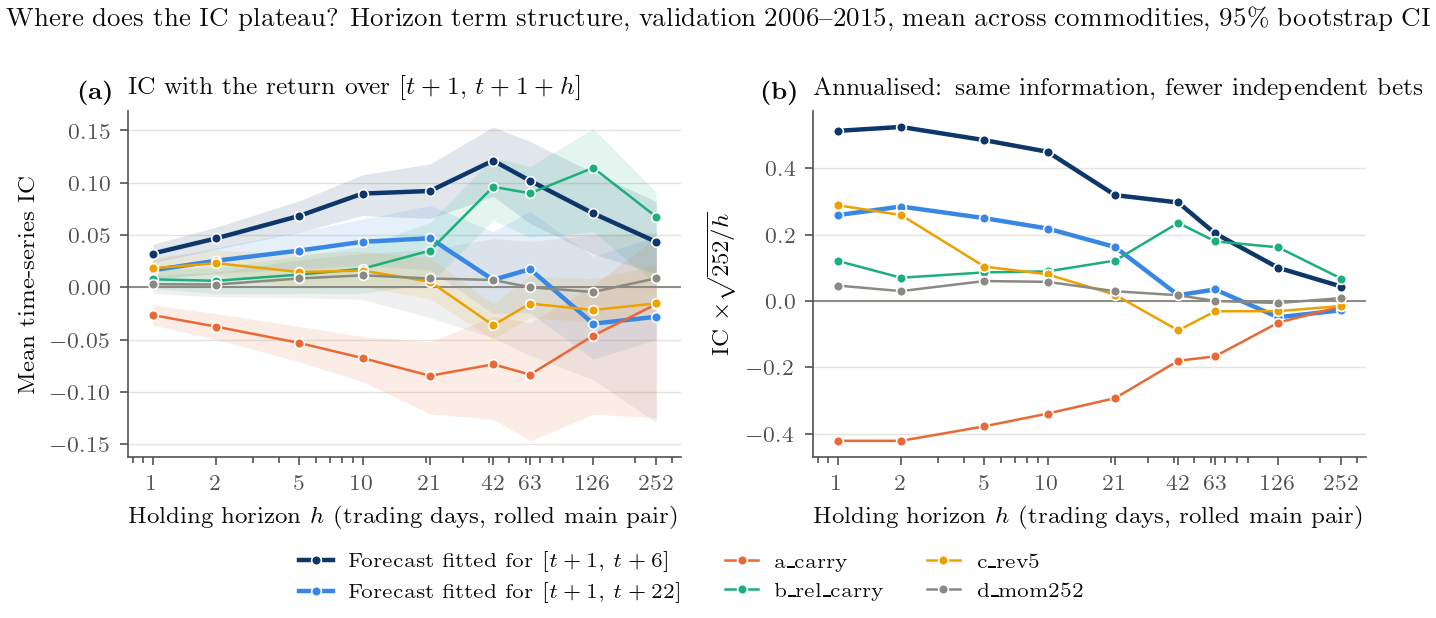

In [13]:
fig = AF.ic_term_structure(term, TERM_LABELS, "valid")
ps.save(fig, "alpha_ic_term_structure");

**读图。** 原始 IC 先升后降：`[t+1, t+6]` 预测在 validation 上于 h≈42 天到顶（0.12），252 天降到 0.04——不是平台，是一个峰。年化 IC 从 h=1 起就单调下降（0.51 → 0.32 @21 天 → 0.20 @63 天）：信息在一两个月内衰减，拿得更久不会得到更多信息，但**换手会少很多**，这正是低频执行（§7c）的出发点。

各 idea 衰减速度不同：A carry 的 IC 在 21–252 天都约 −0.08（train），像一个持续的风险溢价；C 反转 21 天后变号；B 反而在 42–126 天更强。

注意一个陷阱：为 fixed-pair `[t+1, t+22]` 拟合的预测在 rolled 收益上反而不如 `[t+1, t+6]` 的预测（h=21：0.047 vs 0.092）。fixed-pair 的 22 天目标只在合约 22 天内不到期时才有定义（样本选择），而真正持有 22 天的仓位一定会 roll——所以低频策略要用 rolled 收益来评价。

### Paired bootstrap：model 减 model

每次重抽，所有模型用**同一组日期 block**，各自算跨商品平均 IC，再两两相减。差值分布的 95% CI 全在 0 以上记为行模型“胜”一场；胜场最多的模型入选，平局取更简单的。下面以 `[t+1, t+6]` 为例：第一张是点估计矩阵（* = 胜），第二张是**每一对模型**差值的 bootstrap 直方图（行减列，蓝 = 行模型显著更好，橙 = 列模型显著更好，灰 = 无显著差别）。

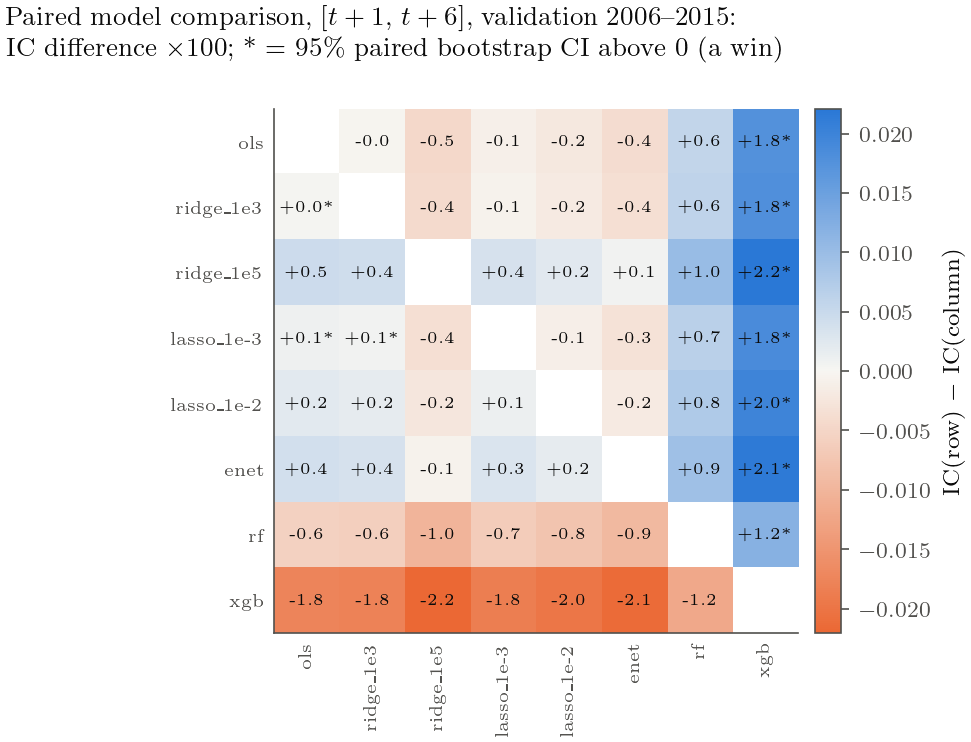

In [14]:
HEAD = "fwd_1_6"
fig = AF.model_win_matrix(mpairs, HEAD)
ps.save(fig, "alpha_model_wins");

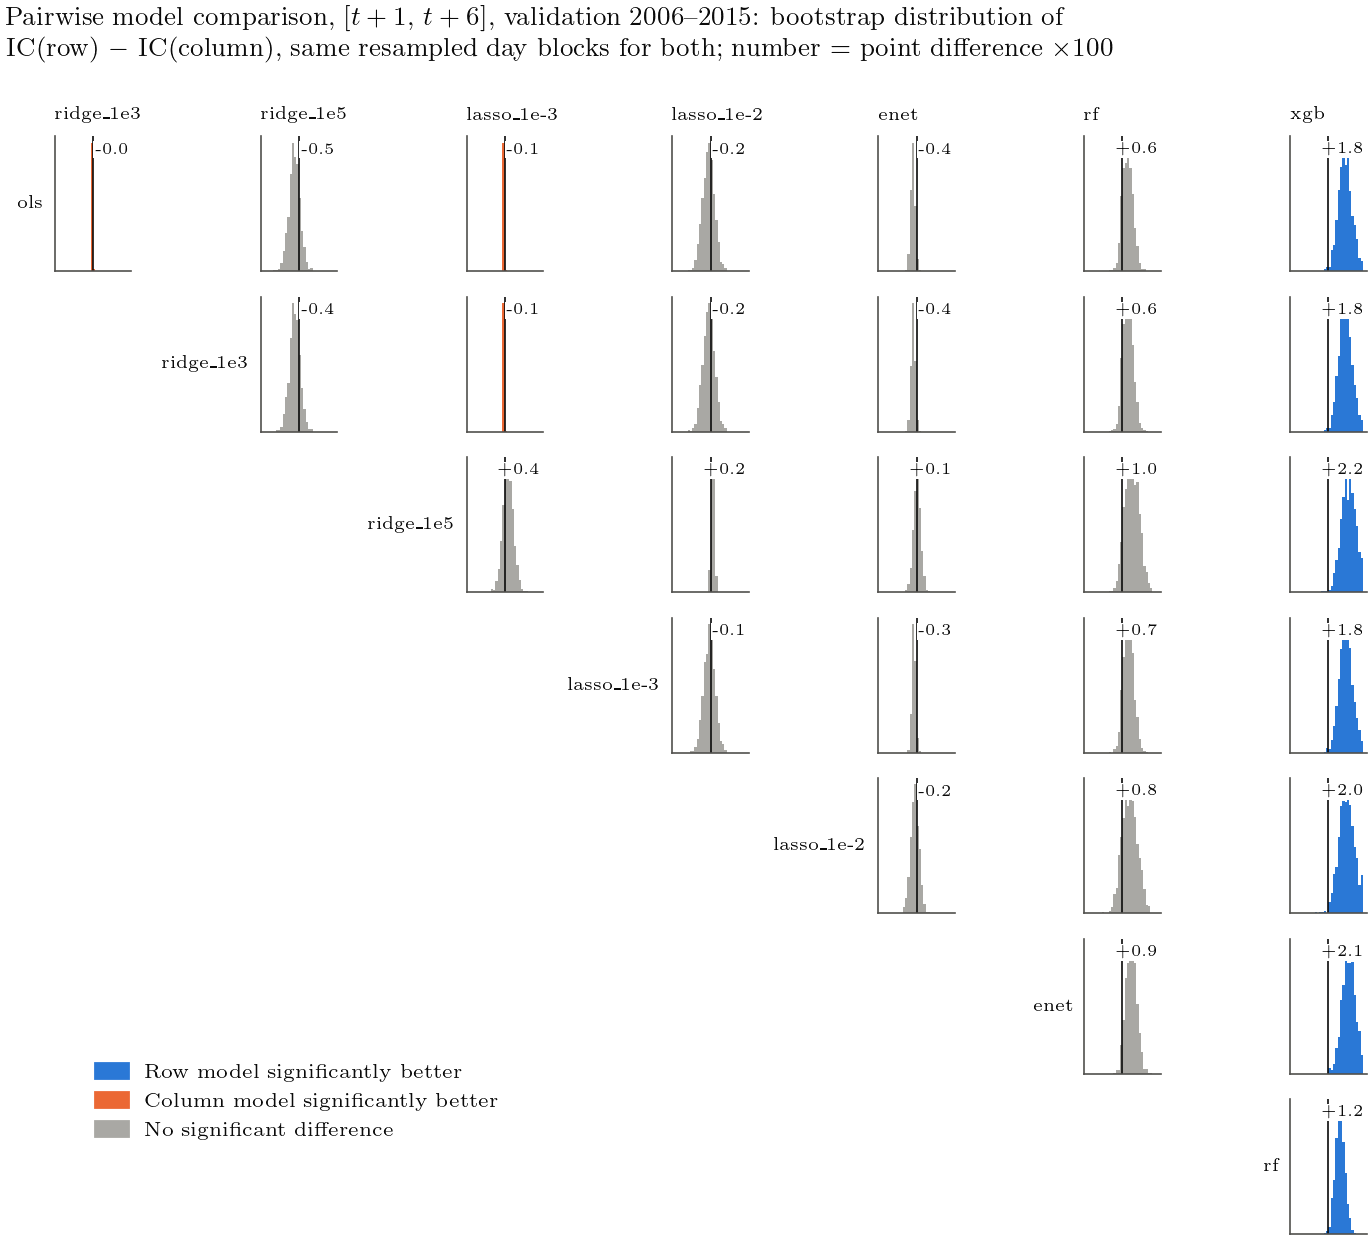

In [15]:
fig = AF.pairwise_diff_grid(mdraws[HEAD], mpairs, HEAD)
ps.save(fig, "alpha_model_diff");

线性模型的系数（train）：方向和大小直接对应“哪个 idea 在贡献信息”。

In [16]:
coefs = pd.read_parquet(OUT / "coefficients.parquet").drop_duplicates(["factor", "target", "model"])
display(coefs.loc[coefs["model"].eq("ols")].pivot(index="factor", columns="target", values="value")
        .reindex(columns=af.TARGETS).round(4))

target,fwd_0_1,fwd_1_2,fwd_1_3,fwd_1_6,fwd_1_11,fwd_1_22
factor,,,,,,
a_carry,0.0095,0.0010,0.0093,0.0127,-0.0058,-0.0364
a_carry_dev,-0.0204,-0.0252,-0.0374,-0.0501,-0.0505,-0.0626
b_curve_carry,NaN,NaN,NaN,NaN,0.0513,0.0446
b_rel_carry,-0.0319,NaN,NaN,NaN,-0.0765,-0.0968
c_rev5,0.0124,0.0266,0.0389,0.0521,0.0397,-0.0012
c_z20,0.0334,-0.0173,-0.0299,-0.0386,-0.0316,0.0138
e_dcurv,NaN,NaN,0.0008,0.0007,NaN,NaN


## 5. 预测诊断（validation 2006–2015）

先看预测本身靠不靠谱，再谈变现：分箱图（预测的自身历史十分位 vs 实现收益）、IC 随时间、每个商品的 IC 及显著性、IC 和商品特征（流动性、tick、成本）的关系。

In [17]:
preds = {t: pd.read_parquet(OUT / f"preds_select_{t}.parquet")[["date", "root", SEL["models"][t]]]
         .rename(columns={SEL["models"][t]: "pred"}) for t in af.TARGETS}
evalf = {t: usable[["date", "root", t]].merge(preds[t], on=["date", "root"]) for t in af.TARGETS}
bins = {t: horizon.bin_returns(S.slice_period(evalf[t], "valid")[["date", "root", t]], S.slice_period(evalf[t], "valid")[["date", "root", "pred"]],
                               col=t, score_col="pred", n_bins=10, min_history=252) for t in af.TARGETS}
display(pd.concat({t: b.set_index("bin")["mean_bps"] for t, b in bins.items()}, axis=1).round(2))

,fwd_0_1,fwd_1_2,fwd_1_3,fwd_1_6,fwd_1_11,fwd_1_22
bin,,,,,,
1,-1.21,-2.34,-4.43,-8.91,-4.69,16.46
2,-0.07,0.04,0.74,0.03,2.08,15.31
3,-0.99,-0.39,-1.19,-1.08,3.84,4.51
4,-0.12,-0.18,0.10,3.31,4.95,8.83
5,0.23,1.28,-0.18,1.58,8.66,14.21
6,1.17,0.05,0.76,3.84,7.74,11.42
7,0.67,0.98,1.87,5.10,8.25,13.98
8,1.91,0.88,2.20,5.63,14.21,25.21
9,1.10,1.85,2.85,7.13,10.81,40.02


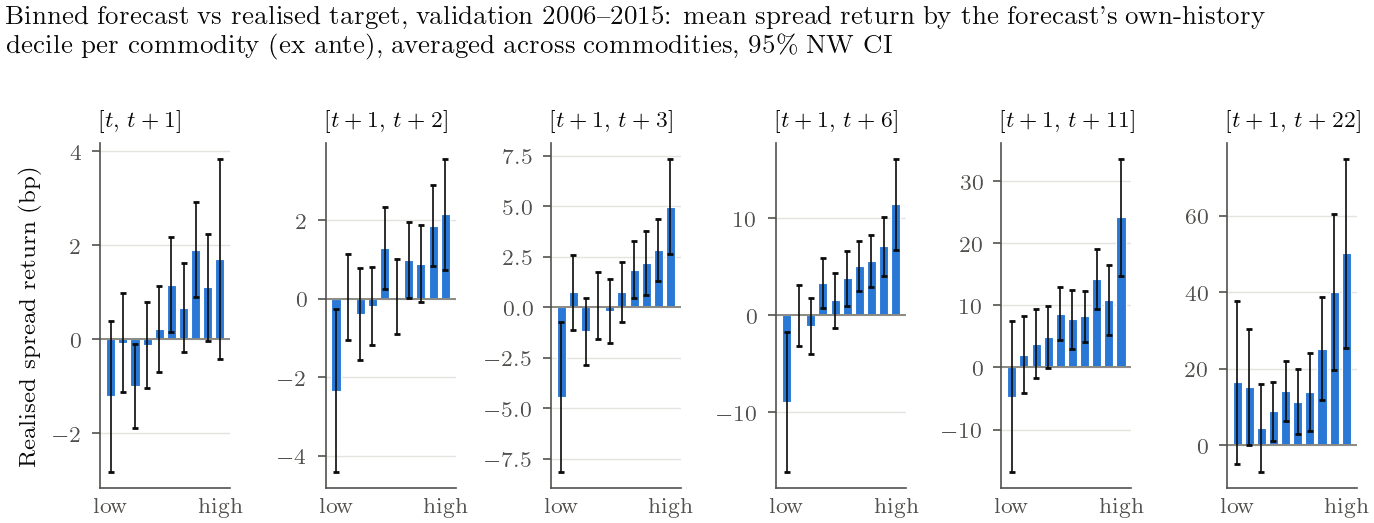

In [18]:
fig = AF.forecast_bins(bins, "validation 2006--2015")
ps.save(fig, "alpha_forecast_bins");

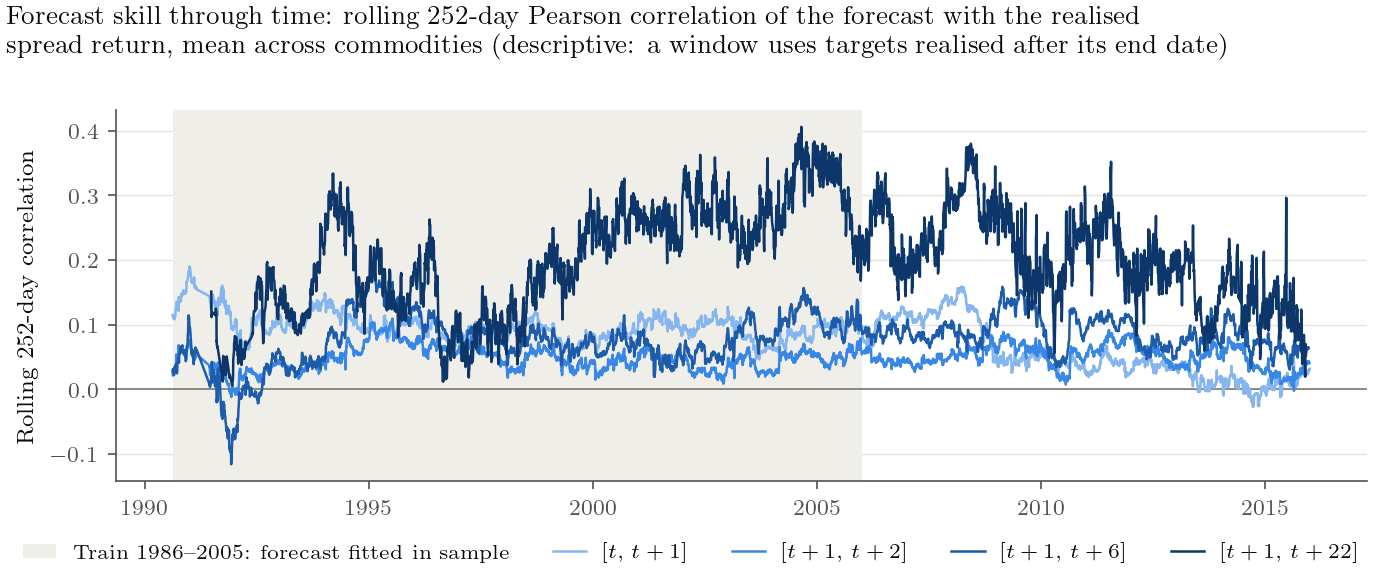

In [19]:
roll = {t: horizon.rolling_ts_ic(evalf[t][["date", "root", t]], evalf[t][["date", "root", "pred"]], col=t, score_col="pred")
        for t in ["fwd_0_1", "fwd_1_2", "fwd_1_6", "fwd_1_22"]}
fig = AF.rolling_ic(roll)
ps.save(fig, "alpha_rolling_ic");

**为什么 `[t+1, t+22]` 的 rolling IC 能到 0.3–0.4？** 不是 look-ahead，三个原因：(1) 252 天窗口里 22 天目标彼此重叠，只有约 11 个独立观测，抽样标准差就有约 0.08，冲到 0.4 很正常；(2) 这里是窗口内的 Pearson 相关（每个窗口重新去均值），比全样本的 rank IC（0.124）更大；(3) 灰色区域是 train，预测在那里是样本内拟合——但 validation 的均值（0.201）和 train（0.204）几乎一样，说明不是过拟合。另外，一个窗口在日期 t 用到的目标要到 t+22 才实现，所以这张图只是描述性的，不能拿来交易。

**Look-ahead 检验。** 预测只用 t 及以前的 settle。验证方法：把预测再人为推迟 L 天（用 t−L 的预测去对同一个目标窗口）。如果预测里混进了 t+1 的信息，L=1 时 IC 会断崖式下跌；实际只是平滑衰减（`[t+1, t+6]`：0.068 → 0.065 → 0.061 → 0.046），和信号自然衰减一致。

target,fwd_1_22,fwd_1_6
lag,,
0,0.1239,0.0682
1,0.1158,0.0648
2,0.1092,0.0613
5,0.0925,0.0461


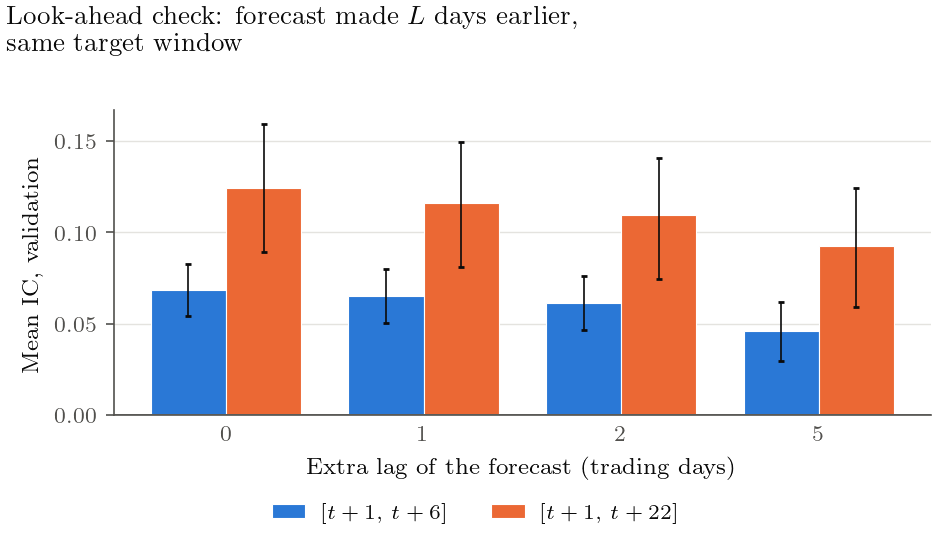

In [20]:
look = pd.read_parquet(OUT / "lookahead_check.parquet")
display(look.pivot(index="lag", columns="target", values="ic").round(4))
fig = AF.lookahead_check(look)
ps.save(fig, "alpha_lookahead_check");

/opt/anaconda3/lib/python3.13/site-packages/pandas/core/nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


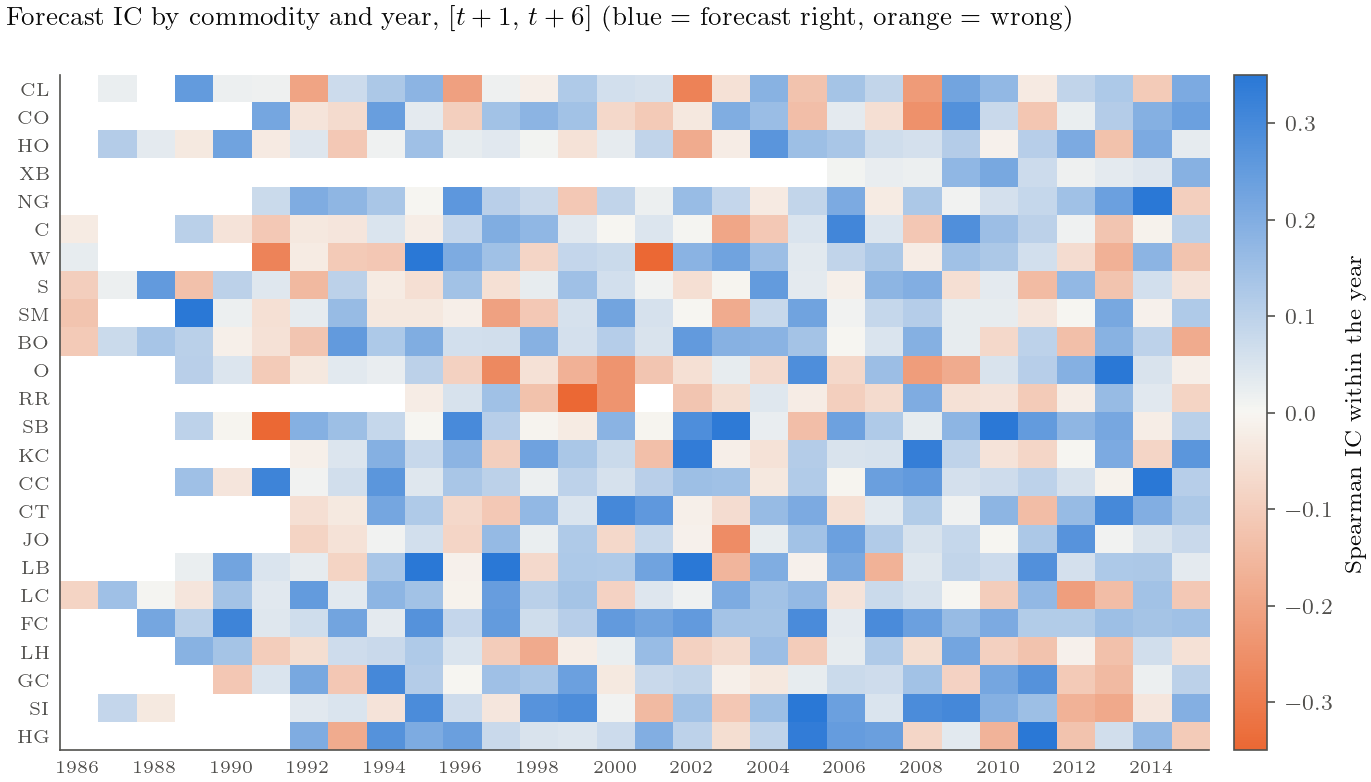

In [21]:
yic = S.yearly_ic(evalf[HEAD], "pred", HEAD)
fig = AF.yearly_root_ic(yic, HEAD, ROOT_ORDER)
ps.save(fig, "alpha_yearly_root_ic");

每个商品的预测 IC 是否显著（validation，`[t+1, t+6]`）：

significant roots: 12/24, positive: 24


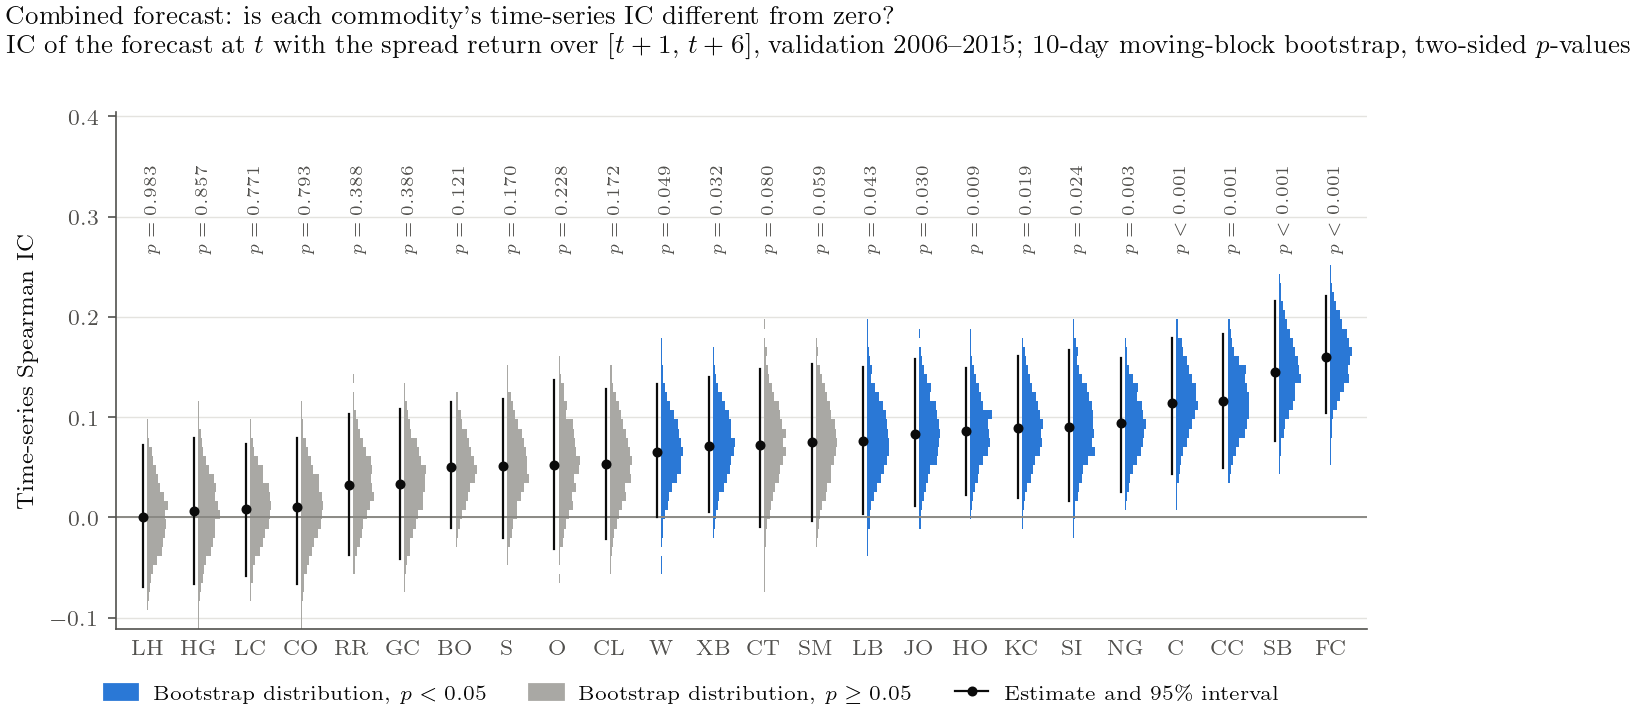

In [22]:
v = S.slice_period(evalf[HEAD], "valid")
mats = S.rank_matrices(v, ["pred"], HEAD)
boot = S.joint_bootstrap(mats, ["pred"], max(BLOCK, 5), n_boot=2000)
rtab = S.ic_table(mats, boot, "pred")
rper = rtab.loc[rtab["root"].ne("ALL")]
rdraws = {r: boot["pred"][1][:, i] for i, r in enumerate(mats["roots"]) if r in set(rper["root"])}
print(f"significant roots: {(rper['p_value'] < 0.05).sum()}/{len(rper)}, positive: {(rper['ic'] > 0).sum()}")
fig = F.bootstrap_ic_distribution(rper, rdraws, "Combined forecast", "the forecast",
                                  r"$[t+1,\,t+6]$, validation 2006--2015", max(BLOCK, 5))
ps.save(fig, "alpha_root_ic_forecast");

In [23]:
from src import v2_signals
rank = pd.read_parquet(config.PROCESSED_DIR / "rank.parquet")
inputs = v2_signals.load_v2_inputs(rank, d=5, k=5, min_adv=100)
chars = P.root_characteristics(panel, inputs.pairs, *S.PERIODS["valid"]).merge(rper[["root", "ic"]], on="root")
display(chars.round(2))

,root,log10_dollar_adv,rel_tick_bp,round_trip_bp,vol_bp,ic
0,BO,8.37,2.54,5.21,4.84,0.05
1,C,8.94,6.05,8.96,13.69,0.11
2,CC,7.93,3.76,6.91,23.80,0.12
3,CL,9.68,1.21,1.94,14.13,0.05
4,CO,9.68,1.17,1.87,9.17,0.01
5,CT,7.79,1.44,4.10,45.51,0.07
6,FC,7.80,2.04,4.09,19.54,0.16
7,GC,8.67,0.85,1.52,0.68,0.03
8,HG,8.35,1.53,2.70,6.87,0.01
9,HO,9.19,0.43,1.04,10.42,0.09


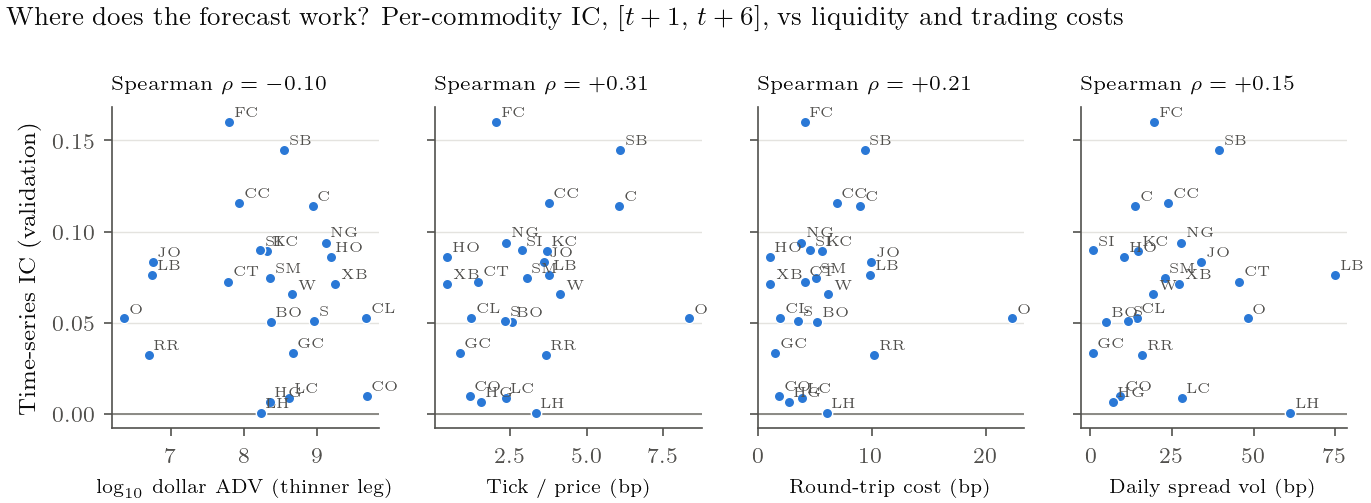

In [24]:
fig = AF.ic_vs_characteristics(chars, {"log10_dollar_adv": r"$\log_{10}$ dollar ADV (thinner leg)",
                                        "rel_tick_bp": "Tick / price (bp)",
                                        "round_trip_bp": "Round-trip cost (bp)",
                                        "vol_bp": "Daily spread vol (bp)"}, HEAD)
ps.save(fig, "alpha_ic_vs_chars");

## 6. 变现（validation，\$1m）

同一个预测，四种规则：时序 `sign`、时序 `linear`、时序 `band`（预期收益超过往返成本才换方向）、截面 `xs`（做多预测最好的 5 个、做空最差的 5 个）。持有期 k = horizon 长度（重叠 sleeve）。成本逐层扣：half-spread → fees → impact。

In [25]:
perf = pd.read_parquet(OUT / "perf_select.parquet")
v = perf.loc[perf["period"].eq("valid") & perf["layer"].isin(["gross", "- impact (all)"])]
display(v.pivot_table(index=["target", "rule"], columns="layer", values=["ann_ret_pct", "sharpe", "turnover_x"]).round(3))
print("headline TS:", SEL["ts"], "\nheadline XS:", SEL["xs"])

ann_ret_pct                sharpe            turnover_x         
layer           - impact (all)  gross - impact (all)  gross - impact (all)    gross
target   rule                                                                      
fwd_1_11 band            0.624  0.928          0.755  1.122         18.659   18.659
         linear          0.469  0.636          0.972  1.319         11.602   11.602
         sign            0.608  0.872          0.838  1.204         18.749   18.749
         xs              0.400  0.670          0.597  1.004         19.441   19.441
fwd_1_2  band           -0.338 -0.077         -0.378 -0.086         16.209   16.209
         linear          0.276  0.757          0.564  1.549         32.426   32.426
         sign           -0.190  1.300         -0.235  1.622         75.467   75.467
         xs             -1.185  1.917         -0.801  1.305        139.662  139.662
fwd_1_22 band            0.769  1.016          0.924  1.221         15.830   15.830
         linear          0.429  0.645          0.662  0.995         14.800   14.800
         sign            0.542  0.764          0.705  0.993         15.205   15.205
         xs             -0.022  0.168         -0.034  0.256         13.643   13.643
fwd_1_3  band            0.052  0.313          0.061  0.370         16.867   16.867
         linear          0.323  0.708          0.689  1.511         26.953   26.953
         sign            0.313  1.264          0.393  1.595         61.818   61.818
         xs              0.146  1.285          0.151  1.335         74.797   74.797
fwd_1_6  band            0.390  0.719          0.479  0.885         20.577   20.577
         linear          0.570  0.812          1.337  1.906         16.993   16.993
         sign            0.846  1.375          1.242  2.024         37.506   37.506
         xs              0.431  0.922          0.631  1.352         34.851   34.851

headline TS: {'target': 'fwd_1_6', 'rule': 'linear', 'valid_net_sharpe': 1.337} 
headline XS: {'target': 'fwd_1_6', 'rule': 'xs', 'valid_net_sharpe': 0.631}


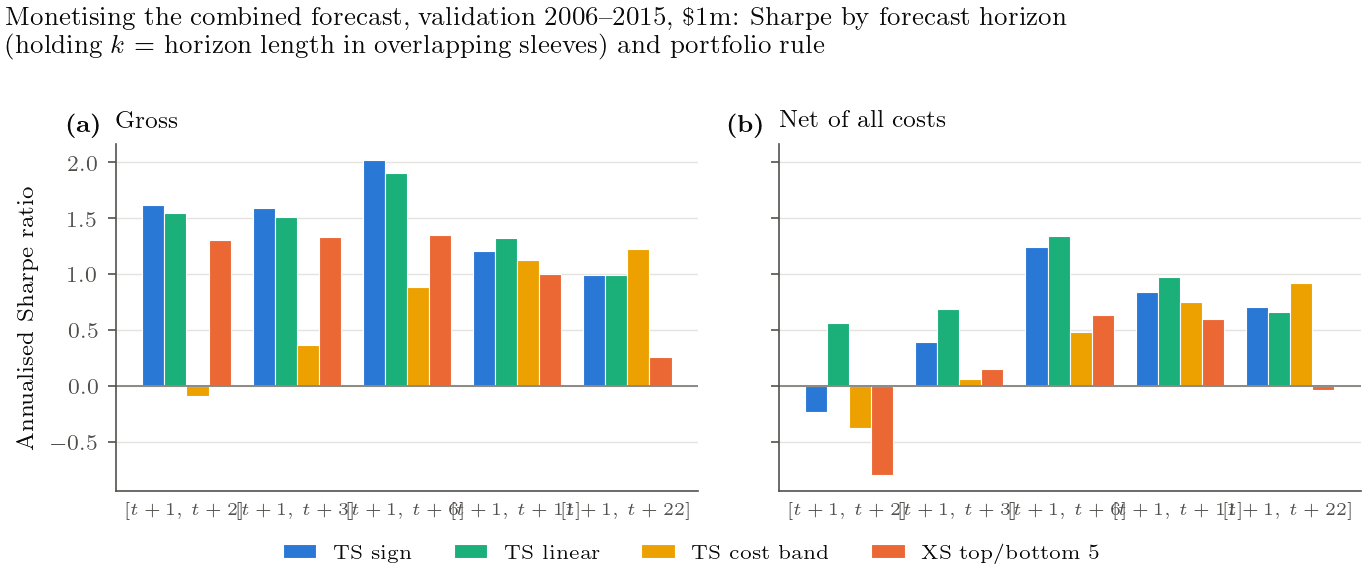

In [26]:
fig = AF.strategy_grid(perf)
ps.save(fig, "alpha_strategy_grid");

## 7. Test 2016–2026（只读一次）

选择在 validation 上冻结（`selection.json`），然后一次性跑全样本；`test_readonce.json` 记录读取时间。**每段用的模型：** train 1986–2005 的预测来自 train 拟合（样本内，NAV 的前 20 年因此偏乐观）；validation 2006–2015 用同一个 train 拟合的模型（真正的样本外）；test 2016–2026 用 train + validation（1986–2015）重新拟合的模型。下表按 period 列出每层成本后的表现。

In [27]:
perf_full = pd.read_parquet(OUT / "perf_full.parquet")
with open(OUT / "results_full.pkl", "rb") as fh:
    results = pickle.load(fh)
print(json.loads((OUT / "test_readonce.json").read_text())["read_at"])
tab = perf_full.loc[perf_full["layer"].isin(["gross", "- impact (all)"])]
display(tab.pivot_table(index=["run", "period"], columns="layer", values=["ann_ret_pct", "sharpe", "t_nw"])
        .reindex(["full", "train", "valid", "test"], level=1).round(3))

2026-10-20T12:10:12.274726


ann_ret_pct                sharpe                  t_nw       
layer                 - impact (all)  gross - impact (all)  gross - impact (all)  gross
run            period                                                                  
ts_100000      full            0.069  0.438          0.114  0.725          0.686  4.373
               train           0.112  0.579          0.202  1.045          0.913  4.729
               valid           0.572  0.812          1.343  1.906          4.063  5.757
               test           -0.478 -0.168         -0.598 -0.210         -1.762 -0.619
ts_1000000     full            0.054  0.438          0.090  0.725          0.542  4.373
               train           0.088  0.579          0.159  1.045          0.719  4.729
               valid           0.570  0.812          1.337  1.906          4.044  5.757
               test           -0.486 -0.168         -0.607 -0.210         -1.792 -0.619
ts_100000_lots full           -0.003  0.001         -0.126  0.033         -1.033  0.290
               train          -0.006  0.001         -0.180  0.047         -1.033  0.290
               valid           0.000  0.000            NaN    NaN            NaN    NaN
               test            0.000  0.000            NaN    NaN            NaN    NaN
xs_1000000     full           -0.259  0.399         -0.310  0.479         -1.903  2.934
               train          -0.251  0.604         -0.312  0.755         -1.436  3.482
               valid           0.431  0.922          0.631  1.352          1.975  4.224
               test           -0.915 -0.464         -0.913 -0.462         -2.671 -1.352

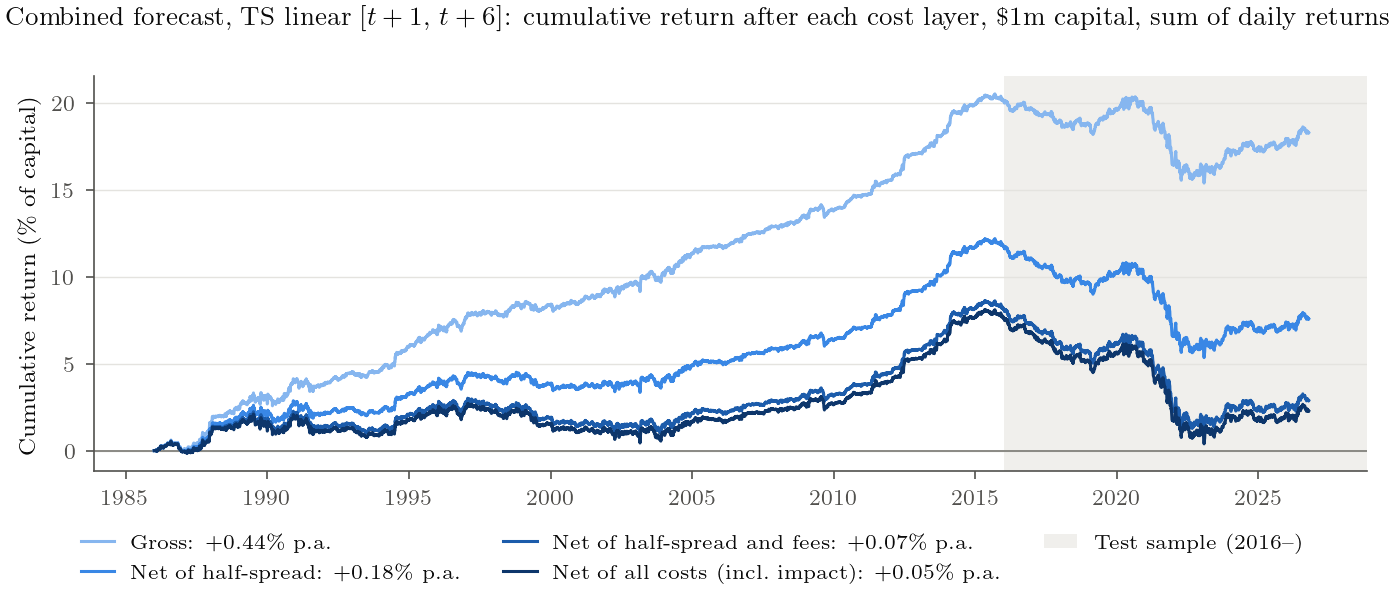

In [28]:
TS = f"Combined forecast, TS {SEL['ts']['rule']} {AF.horizon_label(SEL['ts']['target'])}"
fig = F.nav_by_cost_layer(results["ts_1000000"], TS)
ps.save(fig, "alpha_nav_ts");

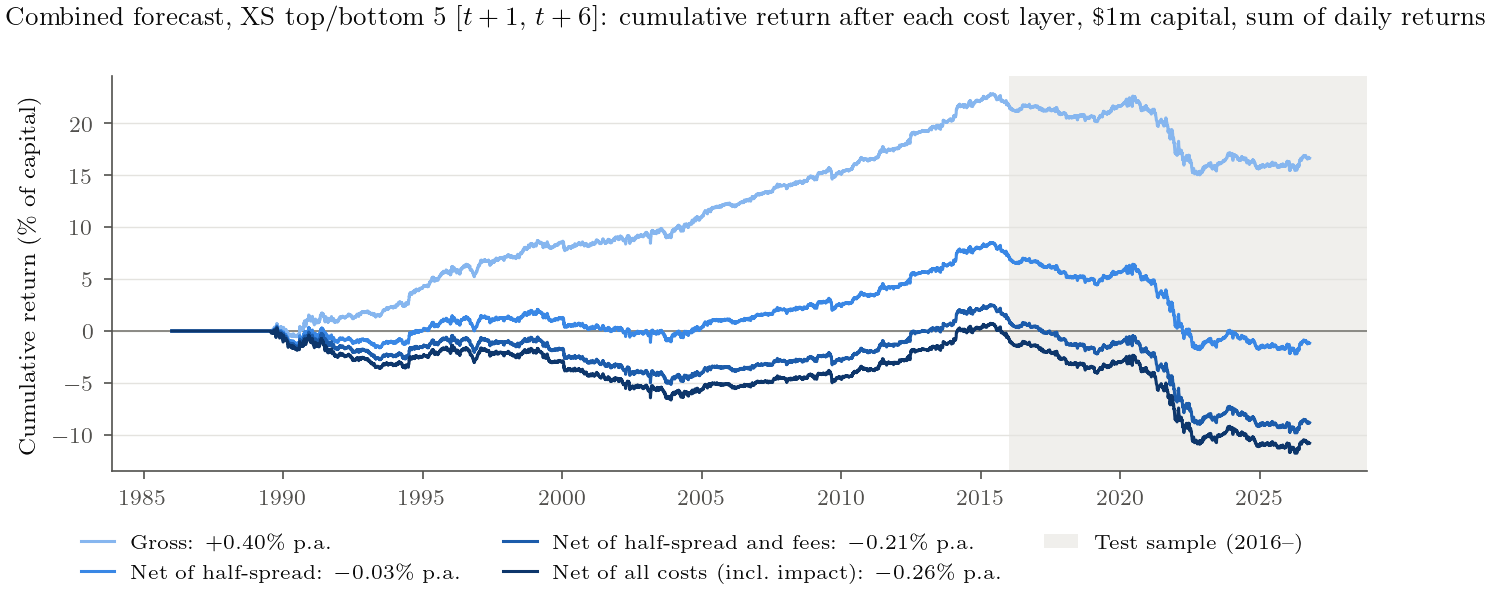

In [29]:
XS = f"Combined forecast, XS top/bottom 5 {AF.horizon_label(SEL['xs']['target'])}"
fig = F.nav_by_cost_layer(results["xs_1000000"], XS)
ps.save(fig, "alpha_nav_xs");

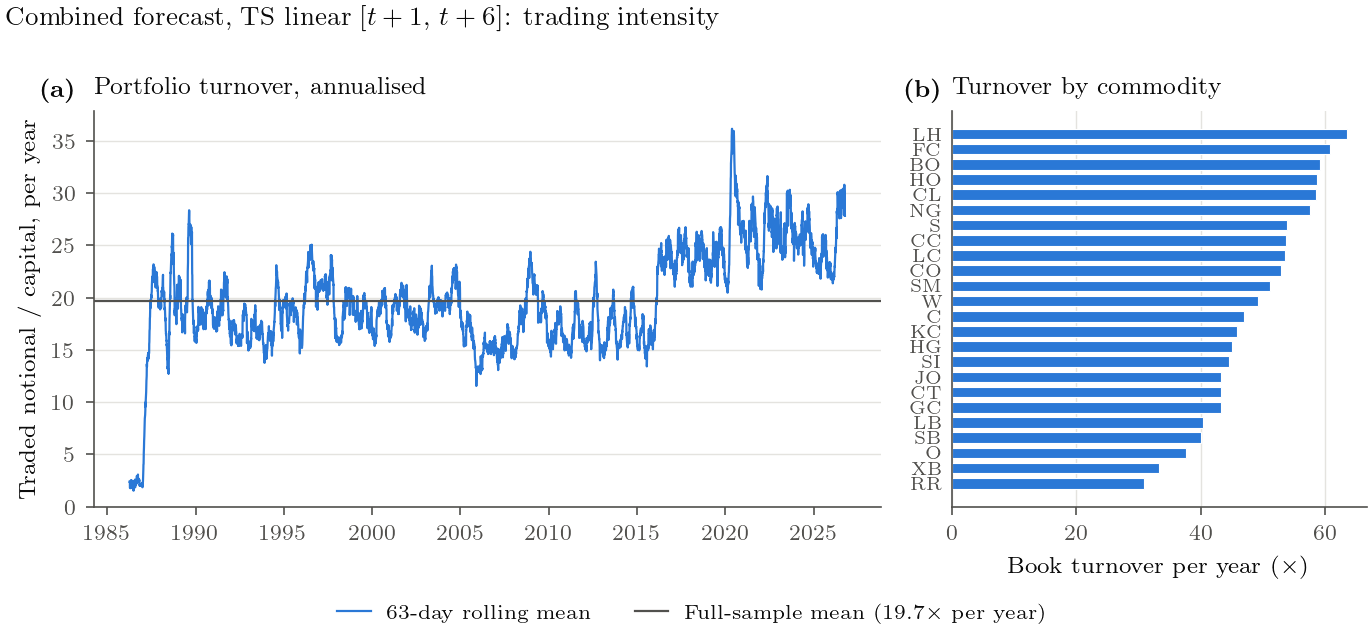

In [30]:
fig = F.turnover(results["ts_1000000"], TS)
ps.save(fig, "alpha_turnover_ts");

### 资本规模：\$100k、整手、容量曲线

half-spread 和 fee 占资本的比例不随规模变，impact 随 √资本 上升；\$100k 时整手取整会让小合约之外的品种很难精确配比。

In [31]:
small = perf_full.loc[perf_full["run"].isin(["ts_1000000", "ts_100000", "ts_100000_lots"]) & perf_full["period"].isin(["valid", "test"])]
display(small.pivot_table(index=["run", "period"], columns="layer", values="sharpe").round(3))
cap = pd.read_parquet(OUT / "capacity_ts.parquet")
display(cap.round(3))

layer              - fees  - half-spread  - impact (all)  gross
run        period                                              
ts_100000  test    -0.598         -0.474          -0.598 -0.210
           valid    1.343          1.516           1.343  1.906
ts_1000000 test    -0.598         -0.474          -0.607 -0.210
           valid    1.343          1.516           1.337  1.906

,capital,gross_bps_yr,half_spread_bps_yr,fee_bps_yr,impact_bps_yr,ann_ret_pct,sharpe
0,100000.0,43.819,25.667,11.27,0.000,0.069,0.114
1,300000.0,43.819,25.667,11.27,0.071,0.068,0.113
2,1000000.0,43.819,25.667,11.27,1.438,0.054,0.090
3,3000000.0,43.819,25.667,11.27,7.623,-0.007,-0.012
4,10000000.0,43.819,25.667,11.27,26.903,-0.200,-0.329
5,30000000.0,43.819,25.667,11.27,62.508,-0.556,-0.908


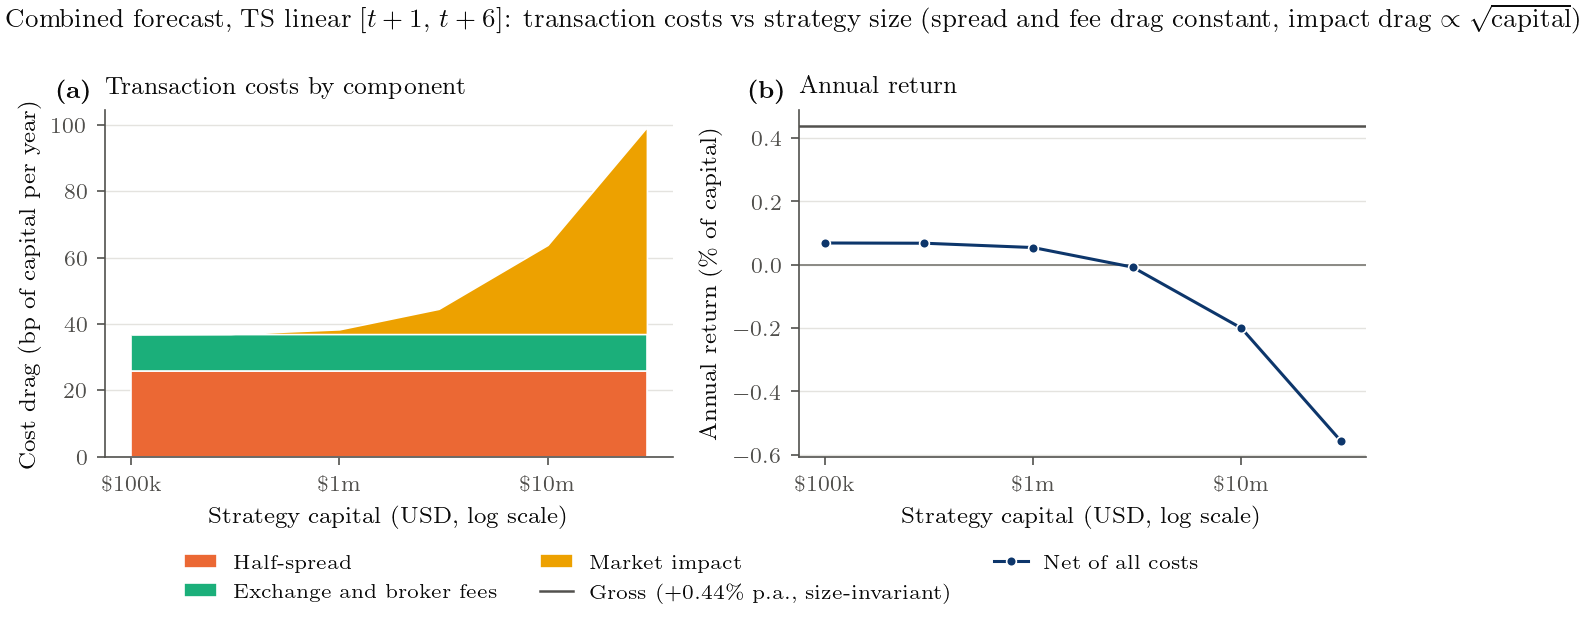

In [32]:
fig = F.capacity(cap, TS)
ps.save(fig, "alpha_capacity_ts");

### 为什么 test 亏钱：预测还在，变现被尾部品种拖垮

下面两张图只是**描述性诊断**，不参与任何选择（test 已读过一次）。先看预测本身：融合预测的 IC 在 test 期是否还在。

In [33]:
full = pd.read_parquet(OUT / "panel_full.parquet")
pf = pd.read_parquet(OUT / "preds_full.parquet").rename(columns={t: f"p_{t}" for t in af.TARGETS})
u = full.loc[full["usable"], ["date", "root"] + af.TARGETS].merge(pf, on=["date", "root"])
rows = []
for per in ("train", "valid", "test"):
    f = S.slice_period(u, per)
    for t in af.TARGETS:
        mats = S.rank_matrices(f, [f"p_{t}"], t)
        boot = S.joint_bootstrap(mats, [f"p_{t}"], max(BLOCK, int(t.split("_")[2]) - int(t.split("_")[1])), n_boot=500)
        a = S.ic_table(mats, boot, f"p_{t}").query("root == 'ALL'").iloc[0]
        rows.append(dict(period=per, target=t, ic=a["ic"], ci_lo=a["ci_lo"], ci_hi=a["ci_hi"]))
pic = pd.DataFrame(rows)
display(pic.pivot(index="target", columns="period", values="ic").reindex(af.TARGETS)[["train", "valid", "test"]].round(4))

period,train,valid,test
target,,,
fwd_0_1,0.0611,0.0208,0.0039
fwd_1_2,0.0211,0.0357,0.0149
fwd_1_3,0.0288,0.0459,0.0171
fwd_1_6,0.0392,0.0682,0.0282
fwd_1_11,0.0618,0.0953,0.0618
fwd_1_22,0.1095,0.1244,0.1412


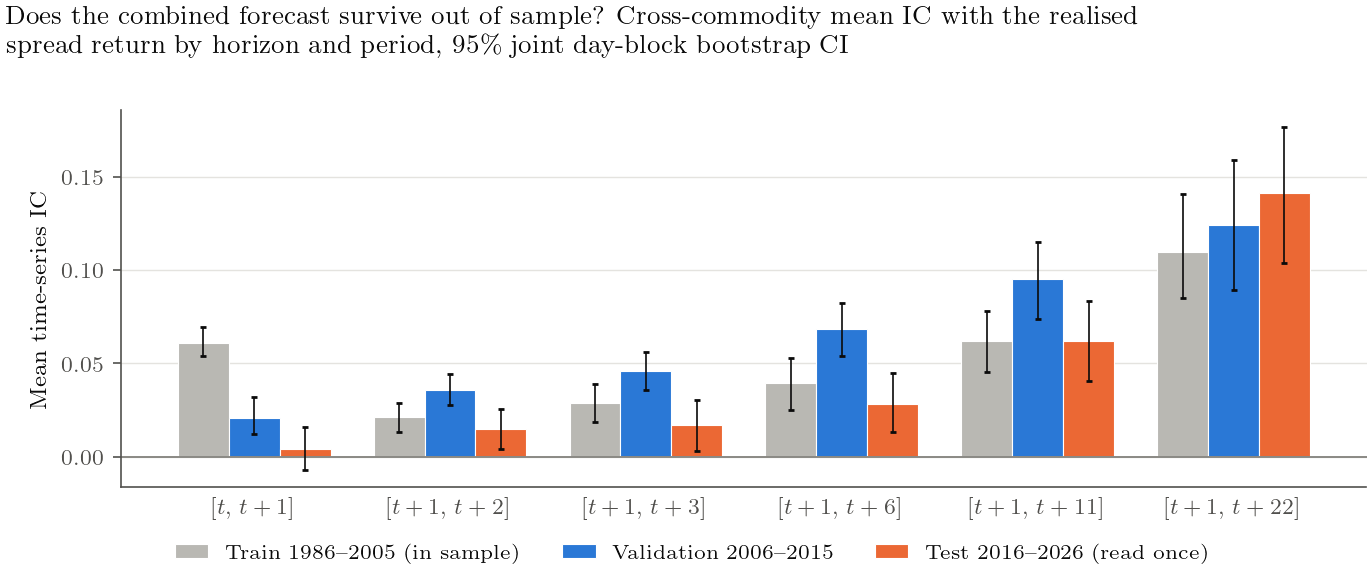

In [34]:
fig = AF.forecast_ic_periods(pic)
ps.save(fig, "alpha_ic_by_period");

test gross bp/yr: -16.8 | excluding LB: 25.5


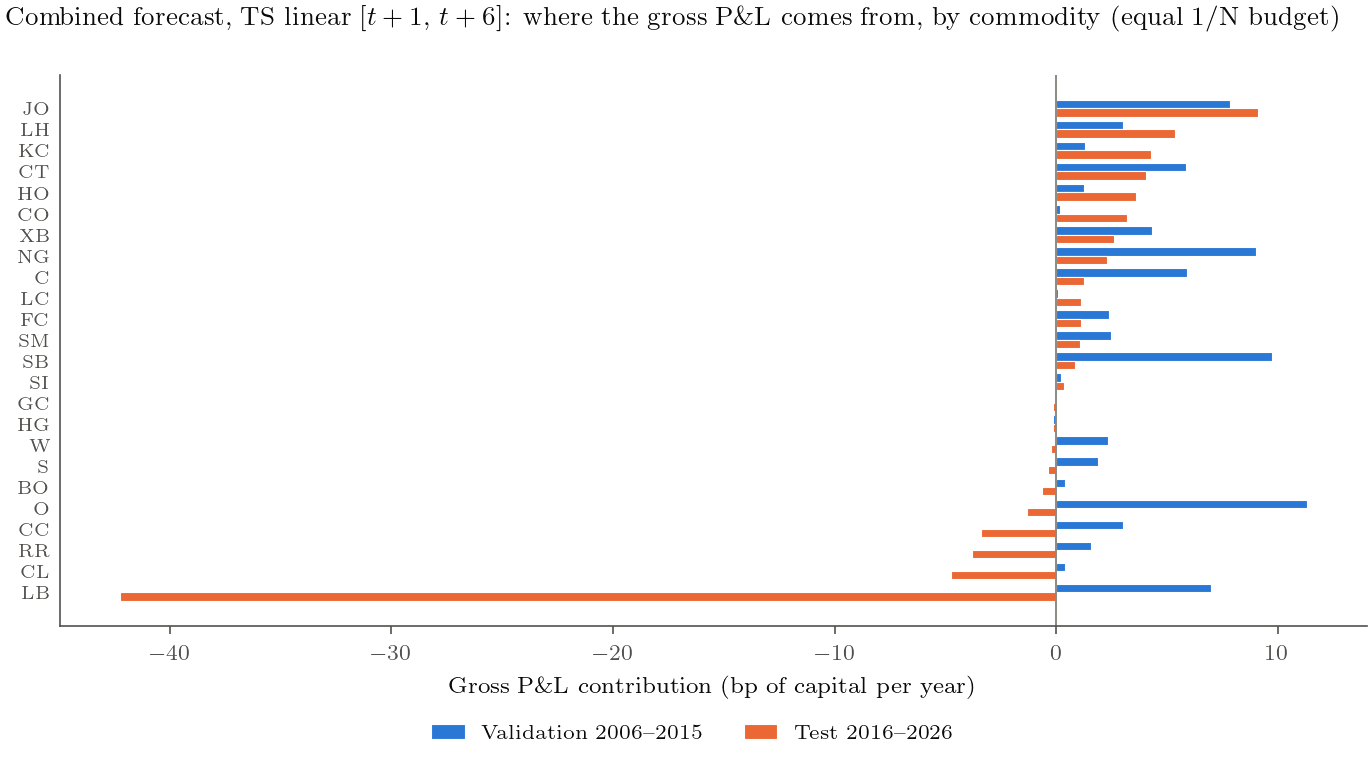

In [35]:
contrib = P.root_contribution(results["ts_1000000"], {k: S.PERIODS[k] for k in ("valid", "test")})
print("test gross bp/yr:", round(contrib["test"].sum(), 1), "| excluding LB:", round(contrib.loc[contrib["root"].ne("LB"), "test"].sum(), 1))
fig = AF.root_contribution(contrib, TS)
ps.save(fig, "alpha_root_contribution");

### 7b. 每个品种的累计收益，以及剔除 LB（事后、描述性）

先按品种拆开看累计 P&L（gross 和扣全部成本），再把 LB 整个拿掉重跑同一个冻结的配置（预测、规则、k 都不变，1/N 的 N 少一个）。**这是看过 test 之后的事后分析**，只用来理解失败原因，不改变 D-030 的结论（D-031）。

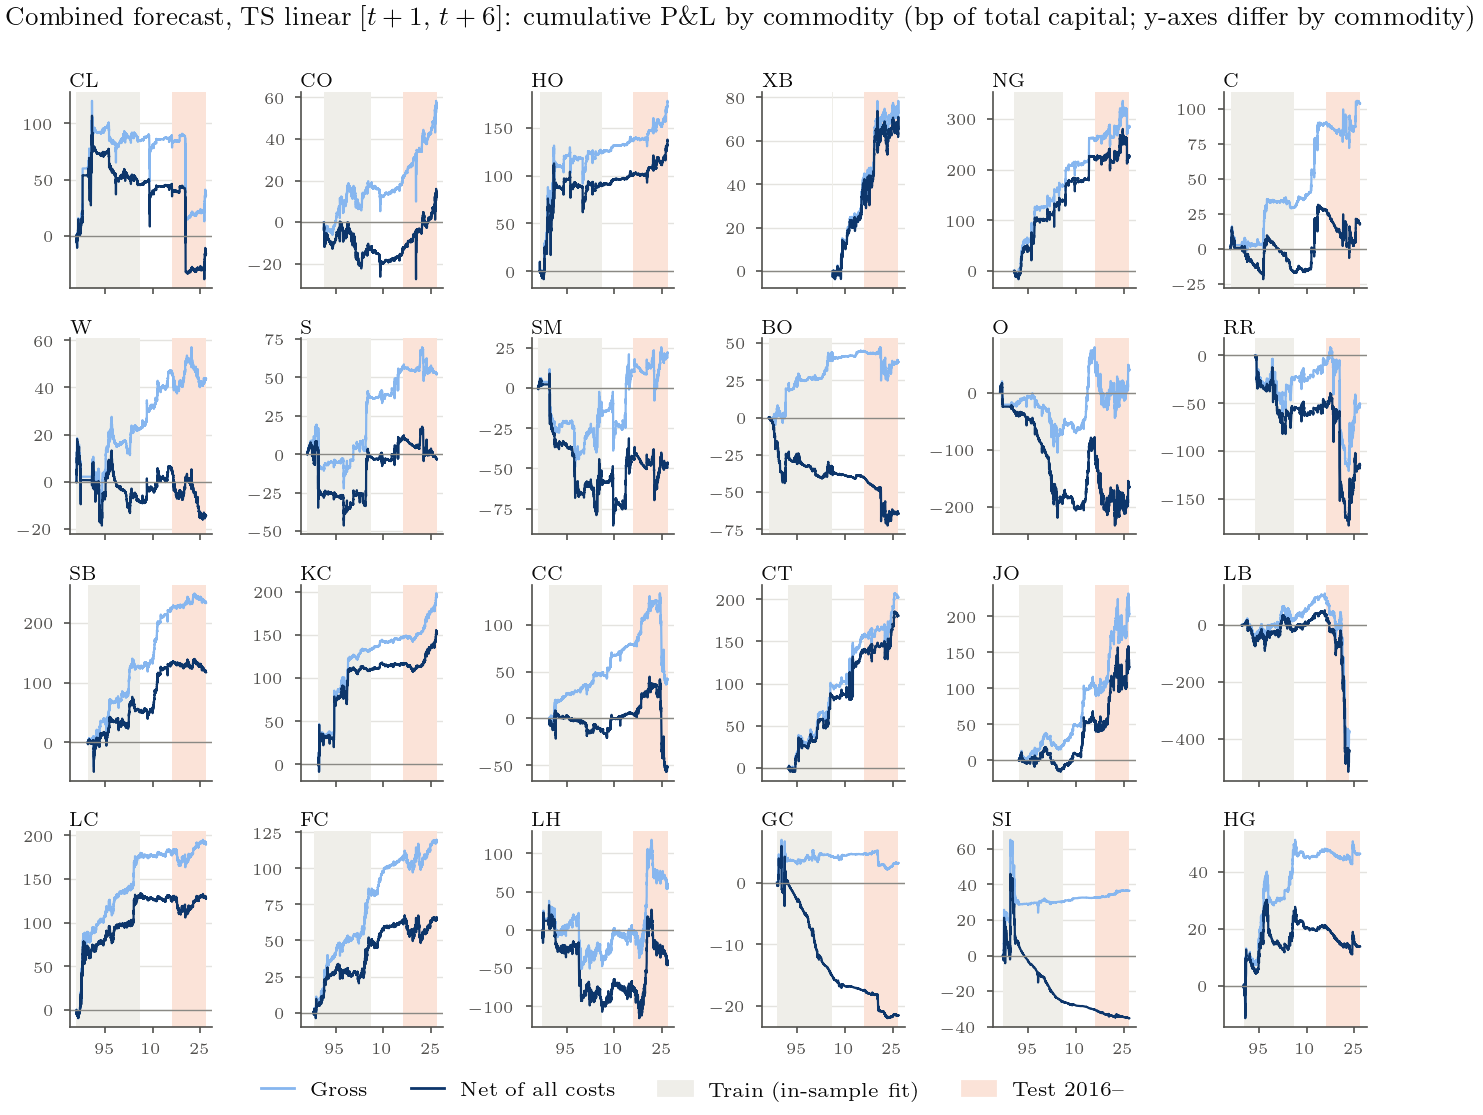

In [36]:
fig = AF.root_cumulative(results["ts_1000000"], TS, ROOT_ORDER)
ps.save(fig, "alpha_root_cum_ts");

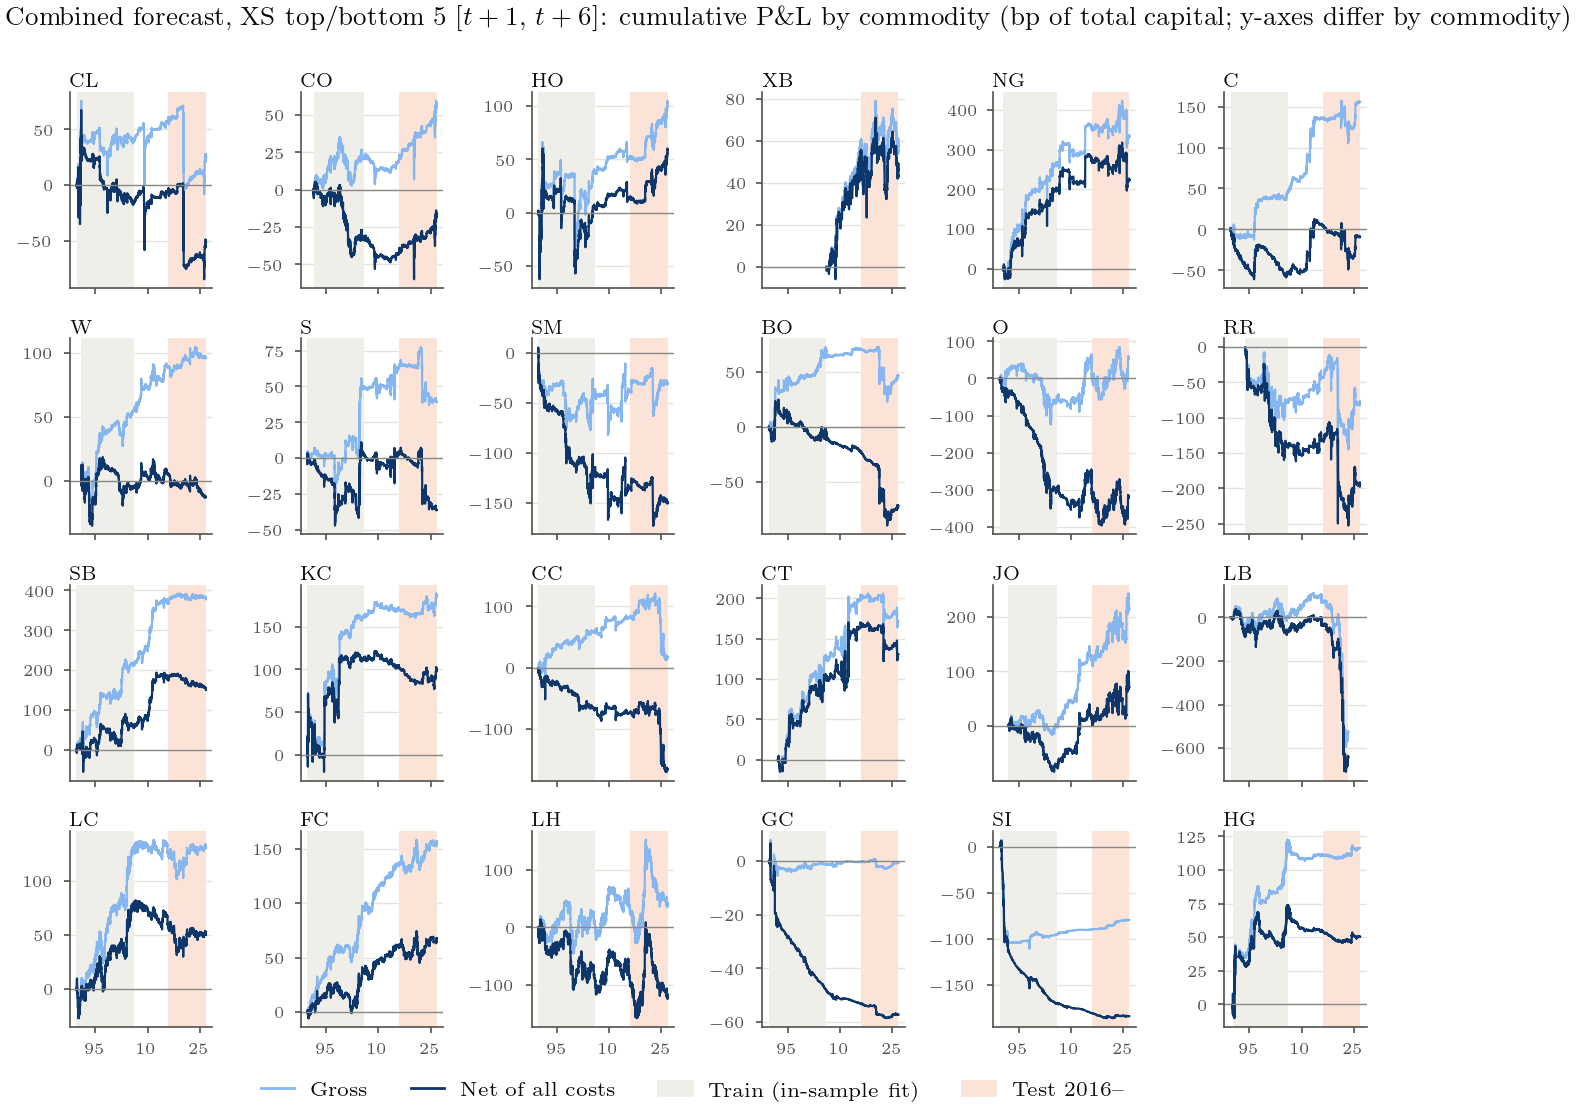

In [37]:
fig = AF.root_cumulative(results["xs_1000000"], XS, ROOT_ORDER)
ps.save(fig, "alpha_root_cum_xs");

In [38]:
perf_exlb = pd.read_parquet(OUT / "perf_full_exLB.parquet")
with open(OUT / "results_full_exLB.pkl", "rb") as fh:
    results_exlb = pickle.load(fh)
both = pd.concat([perf_full.loc[perf_full["run"].isin(["ts_1000000", "xs_1000000"])], perf_exlb])
display(both.loc[both["layer"].isin(["gross", "- impact (all)"])]
        .pivot_table(index=["run", "period"], columns="layer", values=["ann_ret_pct", "sharpe"])
        .reindex(["full", "train", "valid", "test"], level=1).round(3))

ann_ret_pct                sharpe       
layer                  - impact (all)  gross - impact (all)  gross
run             period                                            
ts_1000000      full            0.054  0.438          0.090  0.725
                train           0.088  0.579          0.159  1.045
                valid           0.570  0.812          1.337  1.906
                test           -0.486 -0.168         -0.607 -0.210
ts_1000000_exLB full            0.161  0.540          0.290  0.972
                train           0.094  0.582          0.173  1.069
                valid           0.538  0.768          1.290  1.840
                test           -0.066  0.250         -0.097  0.372
xs_1000000      full           -0.259  0.399         -0.310  0.479
                train          -0.251  0.604         -0.312  0.755
                valid           0.431  0.922          0.631  1.352
                test           -0.915 -0.464         -0.913 -0.462
xs_1000000_exLB full           -0.133  0.526         -0.172  0.685
                train          -0.260  0.604         -0.332  0.776
                valid           0.398  0.868          0.618  1.349
                test           -0.389  0.064         -0.459  0.075

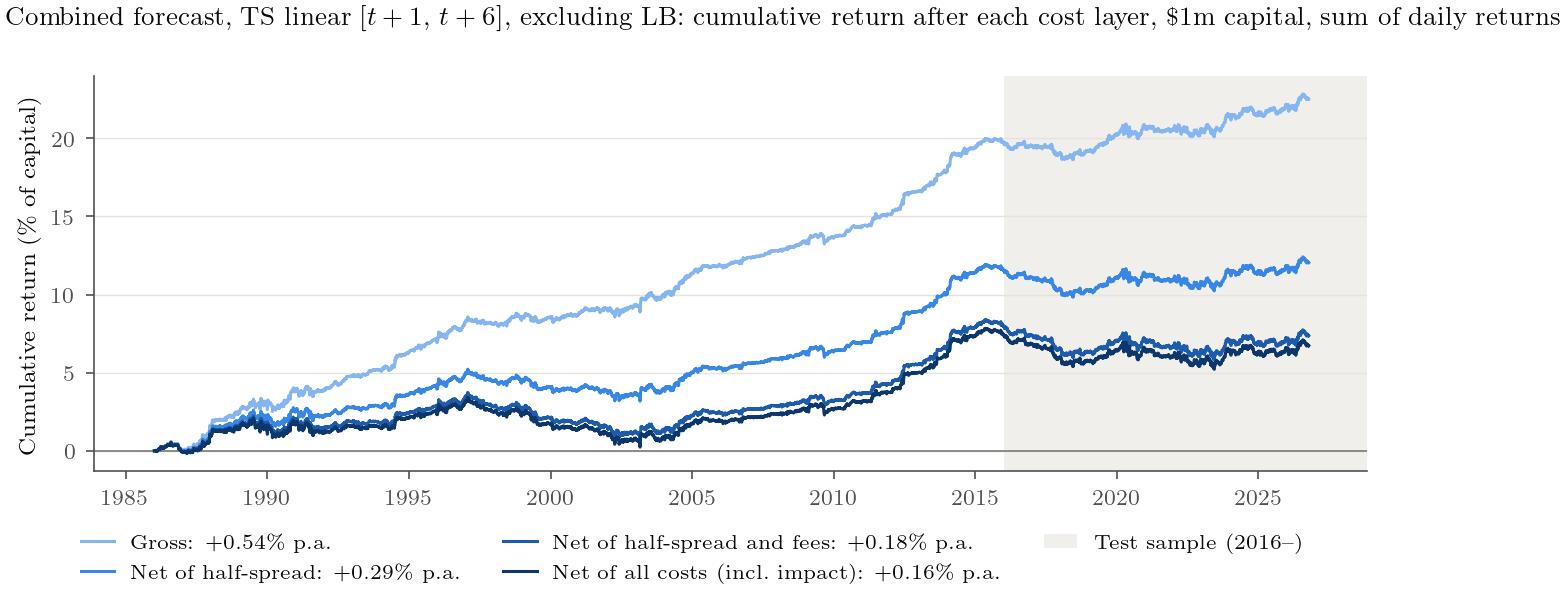

In [39]:
fig = F.nav_by_cost_layer(results_exlb["ts_1000000_exLB"], TS + ", excluding LB")
ps.save(fig, "alpha_nav_ts_exLB");

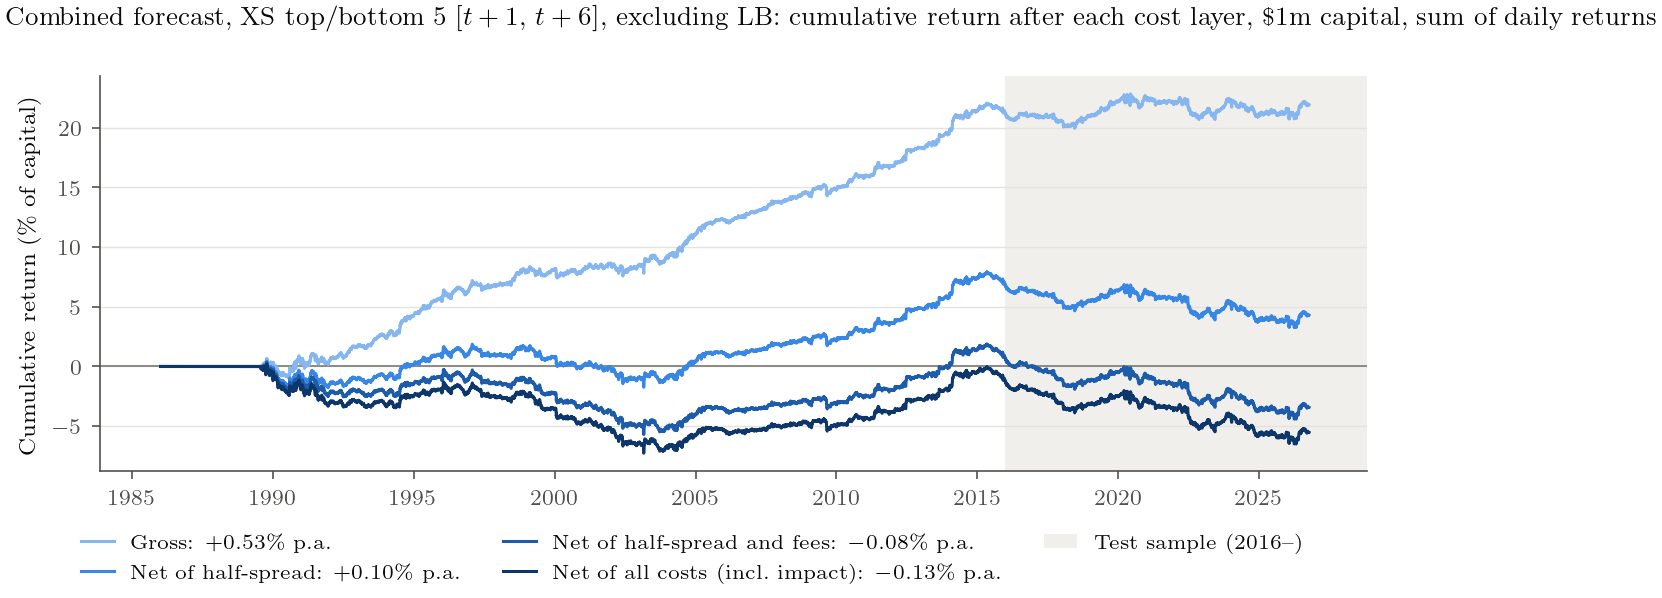

In [40]:
fig = F.nav_by_cost_layer(results_exlb["xs_1000000_exLB"], XS + ", excluding LB")
ps.save(fig, "alpha_nav_xs_exLB");

**剔除 LB 之后**，时序组合 test 的 gross 从 −0.17%/年 变成 +0.25%/年（Sharpe 0.37），但扣完全部成本仍是 −0.07%（Sharpe −0.10）：信息在，只是 5 天 horizon 的换手（约 25×/年）把它吃掉了。截面组合剔除 LB 后 gross 也只有 +0.06%。所以 test 失败有两个原因叠加：一个尾部品种（LB），加上太高的交易频率。下一节针对后者。

### 7c. 低频执行：少交易，能不能留下更多？

同一个预测，两类降频方式，**只在 validation 上比较和选择**（marks 截到 2015 年底）：
- **重叠 sleeve 平滑**：k ∈ {1, 5, 10, 22, 44}，目标仓位 = 过去 k 天信号的平均（每天只调 1/k）。
- **定期调仓**：每 m ∈ {5, 10, 22} 天才更新一次目标，中间持有不动（roll 照常执行）。

预测用 `[t+1, t+6]`、`[t+1, t+11]`、`[t+1, t+22]` 三个，规则 linear / sign。选 validation 扣全部成本后 Sharpe 最高的一组，再跑一次全样本（含 / 不含 LB）。因为 test 已经读过，这组的 test 结果是**事后描述性**的，不能当作样本外证据。

In [41]:
lf = pd.read_parquet(OUT / "perf_lowfreq.parquet")
LF = json.loads((OUT / "lowfreq_selection.json").read_text())
vv = lf.loc[lf["period"].eq("valid") & lf["layer"].isin(["gross", "- impact (all)"])]
display(vv.pivot_table(index=["target", "rule", "kind", "n"], columns="layer", values=["sharpe", "turnover_x"]).round(3))
print("chosen on validation:", LF)

sharpe            turnover_x        
layer                    - impact (all)  gross - impact (all)   gross
target   rule   kind  n                                              
fwd_1_11 linear every 5           1.175  1.591         15.300  15.300
                      10          1.165  1.508         11.676  11.676
                      22          0.704  0.966          9.016   9.016
                k     1           0.895  1.569         25.653  25.653
                      5           1.106  1.530         15.172  15.172
                      10          0.972  1.319         11.602  11.602
                      22          0.746  1.048          9.074   9.074
                      44          0.608  0.888          7.759   7.759
         sign   every 5           0.696  1.188         24.586  24.586
                      10          0.671  1.078         20.684  20.684
                      22          0.428  0.759         17.808  17.808
                k     1           0.738  1.490         35.398  35.398
                      5           1.016  1.443         22.976  22.976
                      10          0.838  1.204         18.749  18.749
                      22          0.672  1.005         15.792  15.792
                      44          0.544  0.855         14.056  14.056
fwd_1_22 linear every 5           0.954  1.308         15.852  15.852
                      10          0.802  1.128         14.491  14.491
                      22          0.688  0.974         13.383  13.383
                k     1           0.873  1.310         20.286  20.286
                      5           0.934  1.300         16.454  16.454
                      10          0.808  1.155         15.417  15.417
                      22          0.653  0.986         14.749  14.749
                      44          0.499  0.821         14.182  14.182
         sign   every 5           1.061  1.385         16.875  16.875
                      10          0.983  1.290         16.363  16.363
                      22          0.751  1.033         15.734  15.734
                k     1           0.912  1.274         17.899  17.899
                      5           1.037  1.343         16.556  16.556
                      10          0.906  1.204         15.801  15.801
                      22          0.687  0.974         15.171  15.171
                      44          0.540  0.820         14.567  14.567
fwd_1_6  linear every 5           1.282  1.839         17.519  17.519
                      10          1.383  1.794         12.106  12.106
                      22          0.648  0.932          8.073   8.073
                k     1           0.750  1.838         36.005  36.005
                      5           1.337  1.906         16.993  16.993
                      10          1.269  1.698         11.282  11.282
                      22          1.023  1.348          7.198   7.198
                      44          0.993  1.264          5.321   5.321
         sign   every 5           0.968  1.922         41.207  41.207
                      10          1.104  1.772         30.922  30.922
                      22          0.444  0.898         22.713  22.713
                k     1          -0.086  1.771         78.261  78.261
                      5           1.242  2.024         37.506  37.506
                      10          1.287  1.894         26.574  26.574
                      22          0.957  1.388         16.881  16.881
                      44          0.945  1.281         12.015  12.015

chosen on validation: {'target': 'fwd_1_6', 'rule': 'linear', 'kind': 'every', 'n': 10, 'valid_net_sharpe': 1.383}


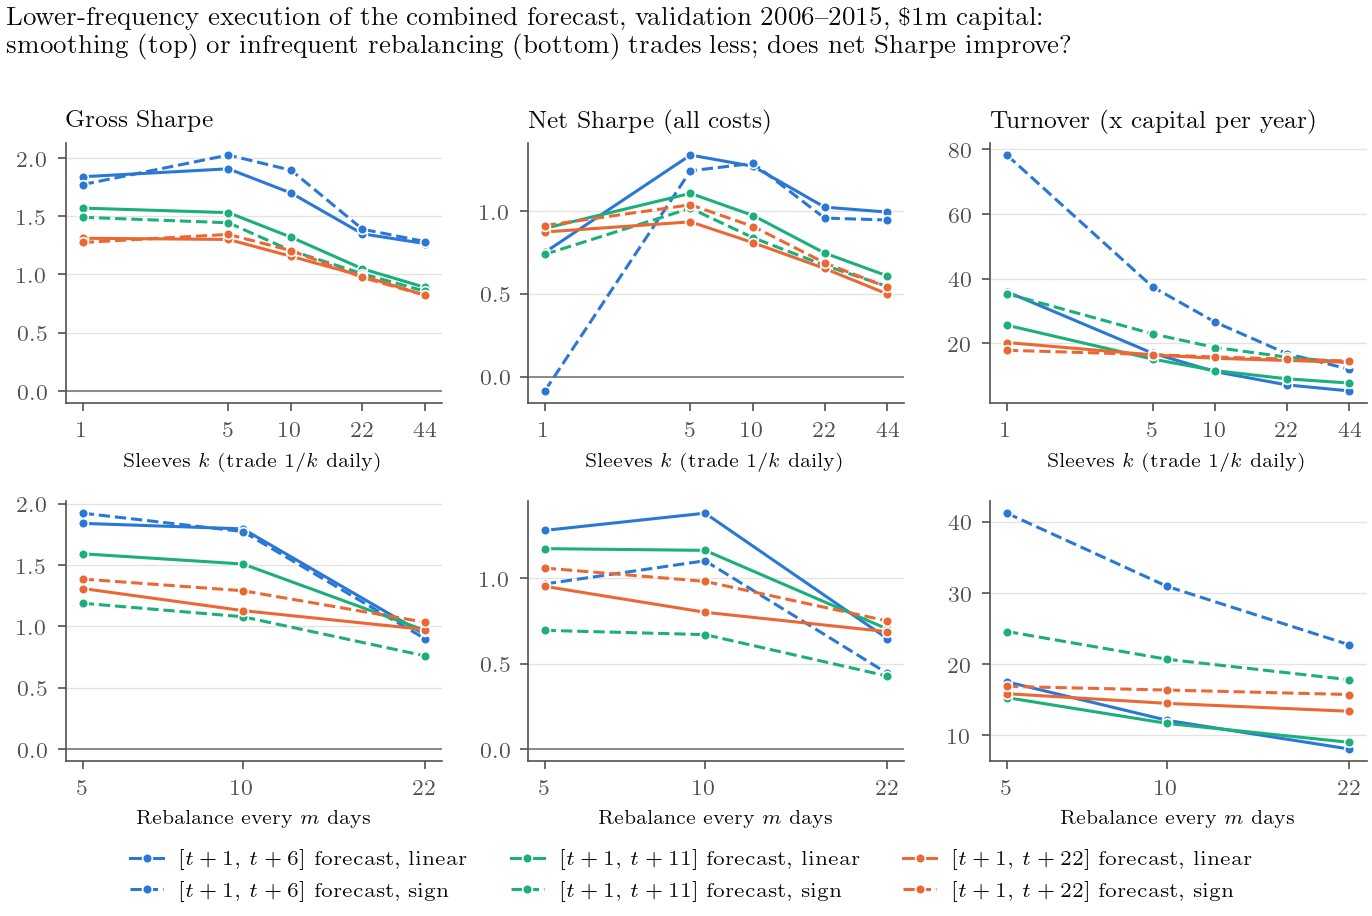

In [42]:
fig = AF.lowfreq_grid(lf, "valid")
ps.save(fig, "alpha_lowfreq_grid");

In [43]:
lf_full = pd.read_parquet(OUT / "perf_lowfreq_full.parquet")
with open(OUT / "results_lowfreq.pkl", "rb") as fh:
    results_lf = pickle.load(fh)
cmp = pd.concat([perf_full.loc[perf_full["run"].eq("ts_1000000")], perf_exlb.loc[perf_exlb["run"].eq("ts_1000000_exLB")], lf_full])
display(cmp.loc[cmp["layer"].isin(["gross", "- impact (all)"])]
        .pivot_table(index=["run", "period"], columns="layer", values=["ann_ret_pct", "sharpe", "turnover_x"])
        .reindex(["full", "train", "valid", "test"], level=1).round(3))
EXEC = f"k={LF['n']} sleeves" if LF["kind"] == "k" else f"rebalance every {LF['n']} days"
LFNAME = f"Combined forecast, TS {LF['rule']} {AF.horizon_label(LF['target'])}, {EXEC}"

ann_ret_pct                sharpe            turnover_x        
layer                  - impact (all)  gross - impact (all)  gross - impact (all)   gross
run             period                                                                   
lowfreq         full           -0.007  0.292         -0.011  0.436         13.875  13.875
                train           0.014  0.401          0.023  0.648         12.274  12.274
                valid           0.612  0.791          1.383  1.794         12.106  12.106
                test           -0.621 -0.373         -0.697 -0.418         18.469  18.469
lowfreq_exLB    full            0.085  0.381          0.137  0.615         13.724  13.724
                train           0.056  0.440          0.092  0.736         12.083  12.083
                valid           0.530  0.702          1.223  1.625         11.993  11.993
                test           -0.272 -0.026         -0.348 -0.033         18.355  18.355
ts_1000000      full            0.054  0.438          0.090  0.725         19.690  19.690
                train           0.088  0.579          0.159  1.045         17.933  17.933
                valid           0.570  0.812          1.337  1.906         16.993  16.993
                test           -0.486 -0.168         -0.607 -0.210         25.431  25.431
ts_1000000_exLB full            0.161  0.540          0.290  0.972         19.450  19.450
                train           0.094  0.582          0.173  1.069         17.659  17.659
                valid           0.538  0.768          1.290  1.840         16.716  16.716
                test           -0.066  0.250         -0.097  0.372         25.290  25.290

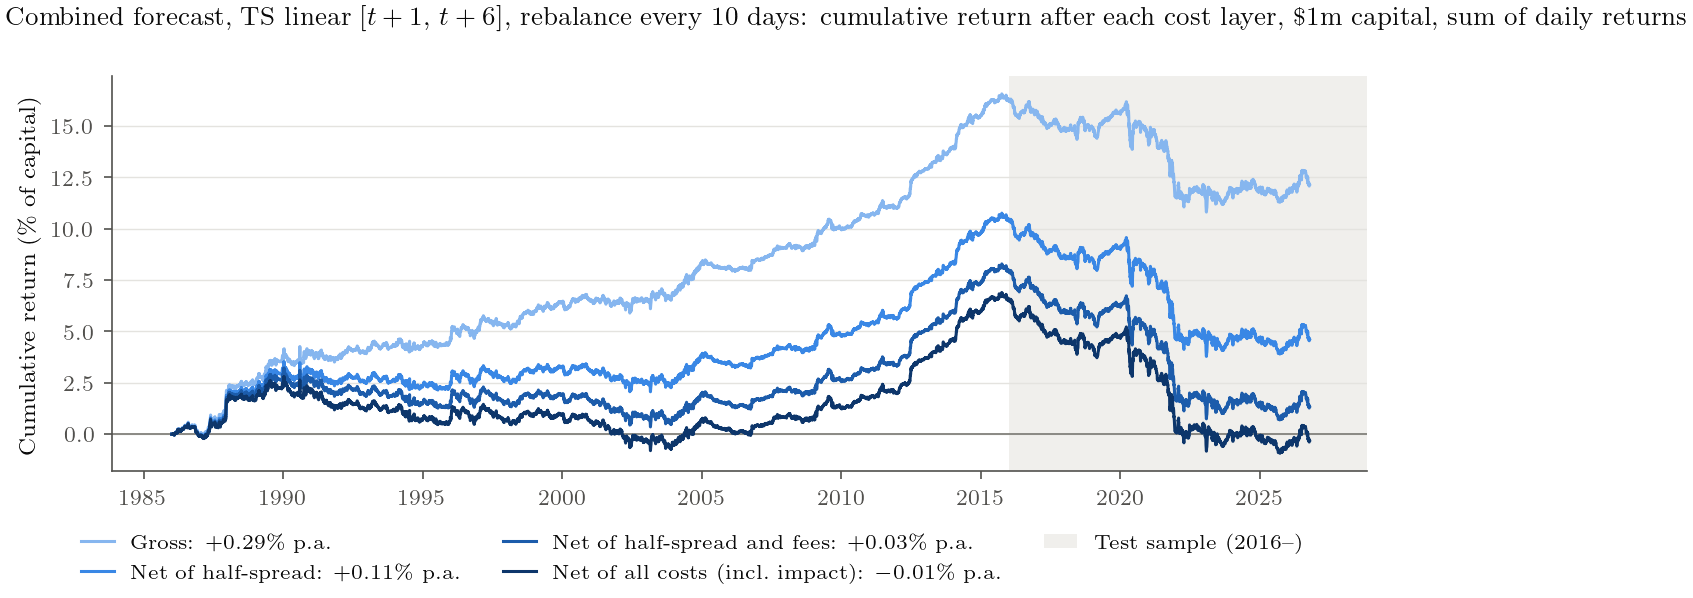

In [44]:
fig = F.nav_by_cost_layer(results_lf["lowfreq"], LFNAME)
ps.save(fig, "alpha_nav_lowfreq");

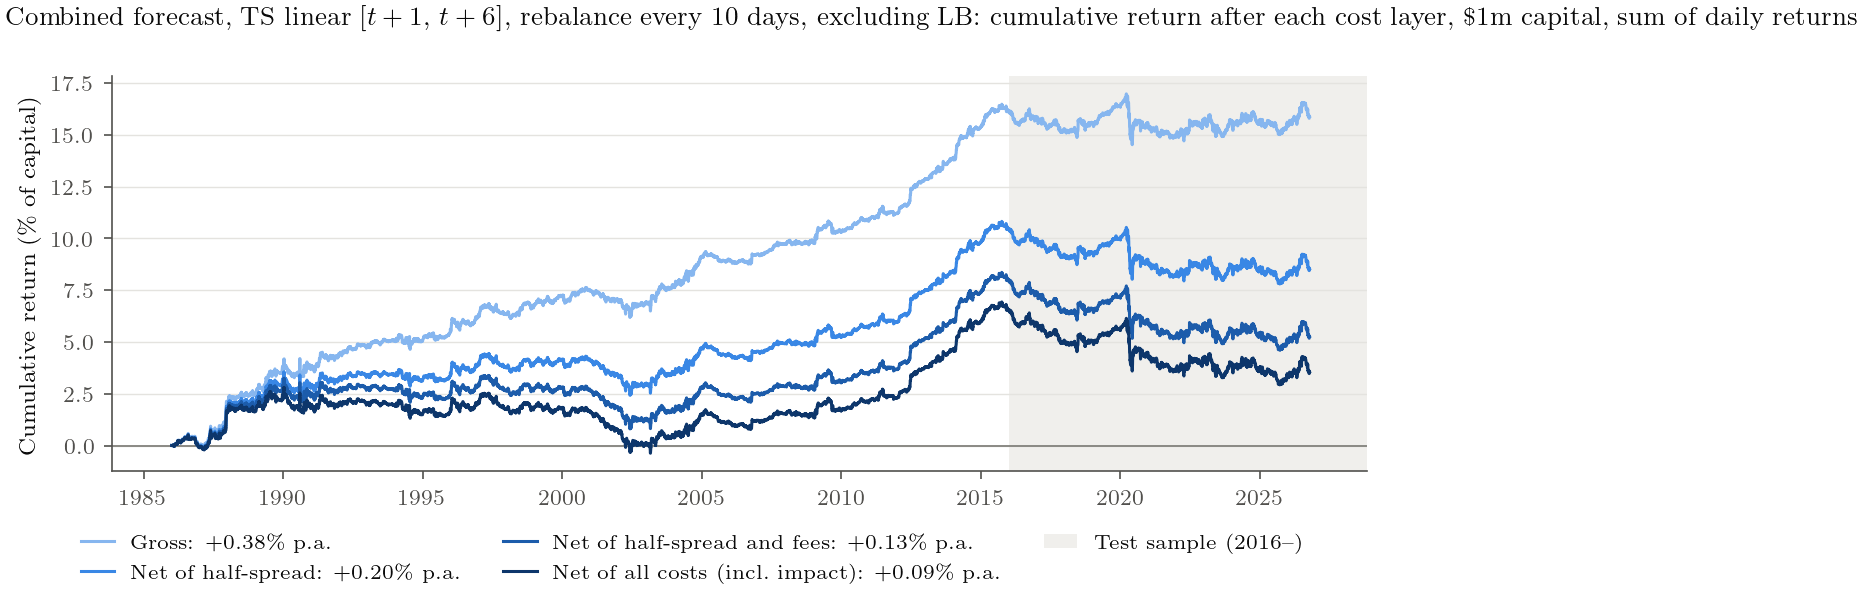

In [45]:
fig = F.nav_by_cost_layer(results_lf["lowfreq_exLB"], LFNAME + ", excluding LB")
ps.save(fig, "alpha_nav_lowfreq_exLB");

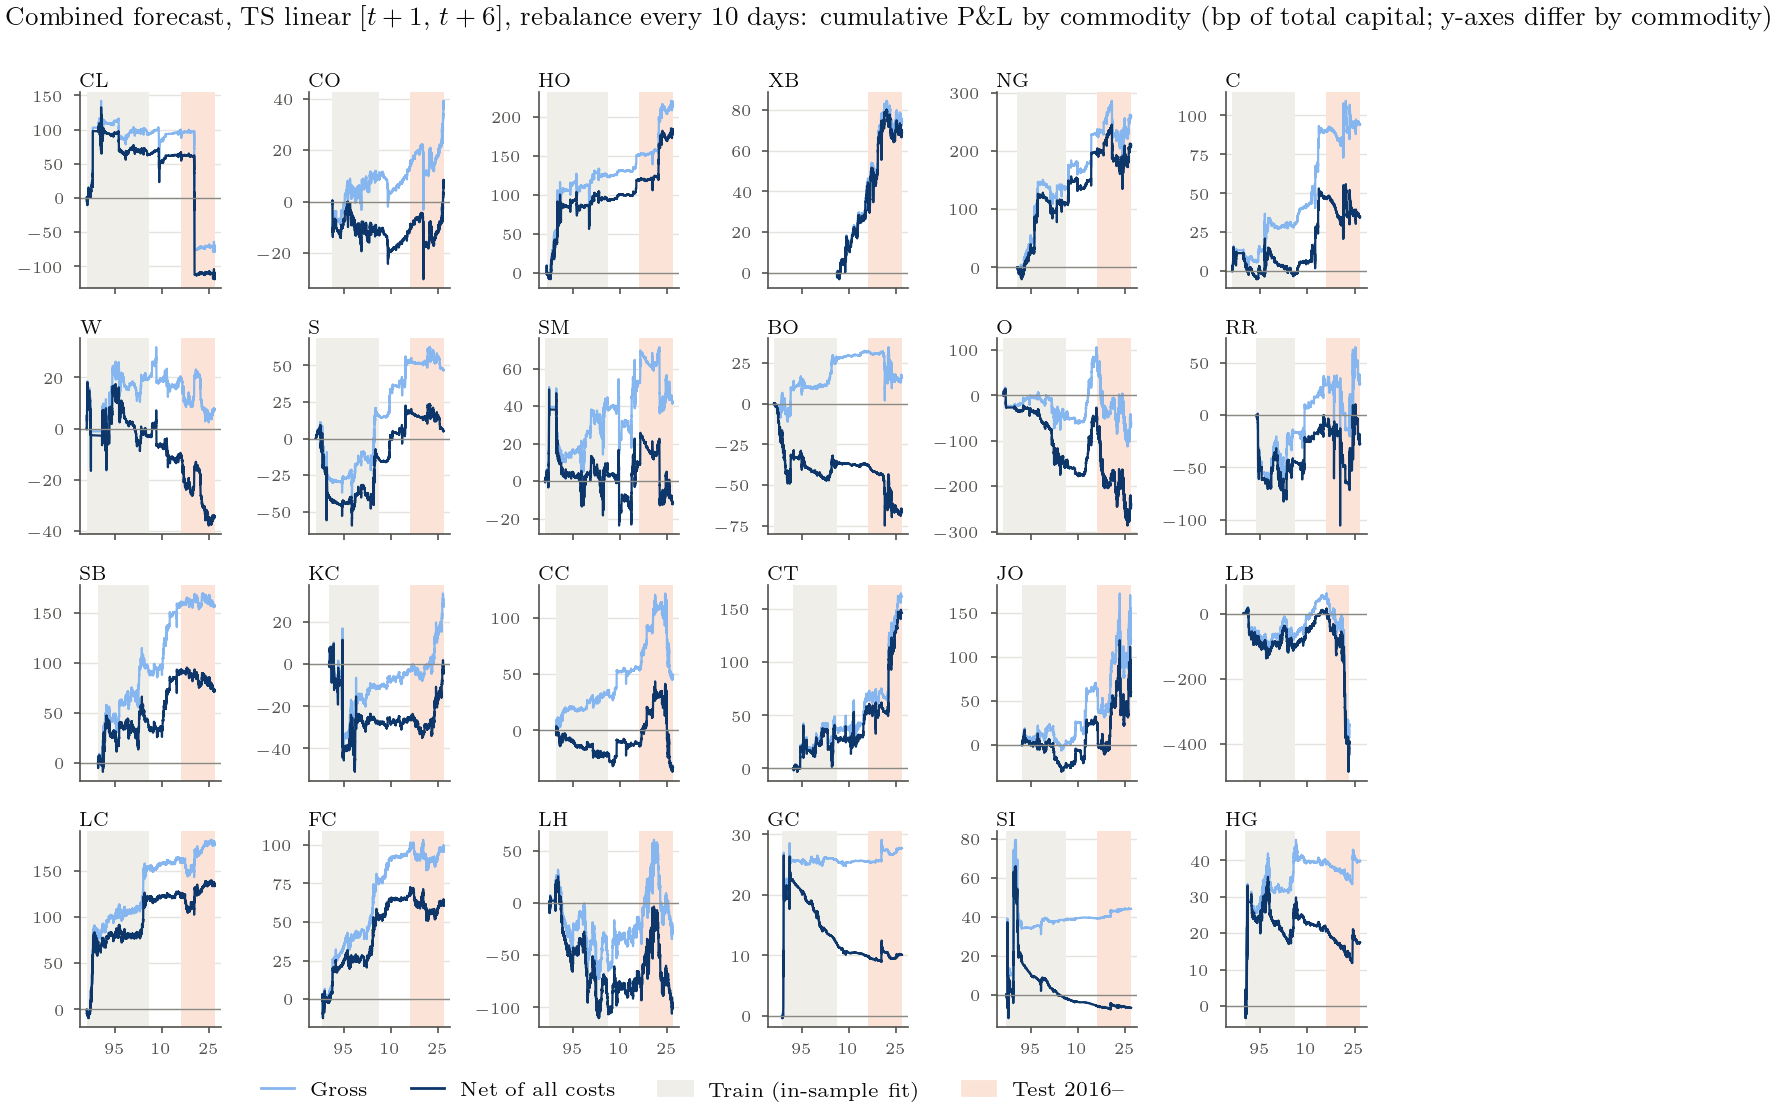

In [46]:
fig = AF.root_cumulative(results_lf["lowfreq"], LFNAME, ROOT_ORDER)
ps.save(fig, "alpha_root_cum_lowfreq");

**读图（validation）。** 降频确实减少换手（k=1 → 44：36× → 5×），但 gross Sharpe 也跟着下降（1.84 → 1.26）：仓位跟得越慢，用的预测越旧，正好对应上面年化 IC 的衰减。净 Sharpe 的最优点在 k≈5–10 或每 5–10 天调仓，k=22 已经过头。validation 选出的是 `[t+1, t+6]`、linear、每 10 天调仓（净 Sharpe 1.38 vs 头条 1.34，提升有限）；它在 test 上同样为负（gross −0.37%，net −0.62%；剔除 LB 后 net −0.27%）。

**再看几组有代表性的低频配置（事后、描述性）。** 下表和下图在 test 读过之后才比较，只用来理解，不用来选择。

In [47]:
desc = pd.read_parquet(OUT / "perf_lowfreq_desc.parquet")
desc_daily = pd.read_parquet(OUT / "daily_lowfreq_desc.parquet")
d = desc.loc[desc["period"].isin(["valid", "test"])]
tab = d.pivot_table(index=["run", "period"], columns="layer", values="sharpe")[["gross", "- impact (all)"]]
tab["net_ret_pct"] = d.loc[d["layer"].eq("- impact (all)")].set_index(["run", "period"])["ann_ret_pct"]
tab["turnover_x"] = d.loc[d["layer"].eq("gross")].set_index(["run", "period"])["turnover_x"]
display(tab.round(3))

layer                                gross  - impact (all)  net_ret_pct  turnover_x
run                          period                                                
fwd_1_22|linear|k=22         test    0.619           0.408        0.415      16.025
                             valid   0.986           0.653        0.423      14.749
fwd_1_22|linear|k=22|exLB    test    0.598           0.370        0.343      15.825
                             valid   1.024           0.685        0.423      14.671
fwd_1_22|sign|every=22       test    0.639           0.452        0.566      16.378
                             valid   1.033           0.751        0.642      15.734
fwd_1_22|sign|every=22|exLB  test    0.787           0.578        0.645      16.225
                             valid   1.079           0.794        0.649      15.649
fwd_1_6|linear|every=22      test   -0.494          -0.675       -0.616      12.944
                             valid   0.932           0.648        0.265       8.073
fwd_1_6|linear|every=22|exLB test   -0.270          -0.475       -0.382      12.832
                             valid   0.902           0.622        0.249       8.008
fwd_1_6|linear|k=22          test    0.253           0.016        0.010      11.620
                             valid   1.348           1.023        0.307       7.198
fwd_1_6|linear|k=22|exLB     test    0.316           0.061        0.034      11.525
                             valid   1.277           0.963        0.287       7.149
fwd_1_6|linear|k=44          test    0.482           0.284        0.155       8.848
                             valid   1.264           0.993        0.264       5.321
fwd_1_6|linear|k=44|exLB     test    0.511           0.294        0.144       8.748
                             valid   1.190           0.930        0.247       5.288
fwd_1_6|linear|k=5           test   -0.210          -0.607       -0.486      25.431
                             valid   1.906           1.337        0.570      16.993
fwd_1_6|linear|k=5|exLB      test    0.372          -0.097       -0.066      25.290
                             valid   1.840           1.290        0.538      16.716

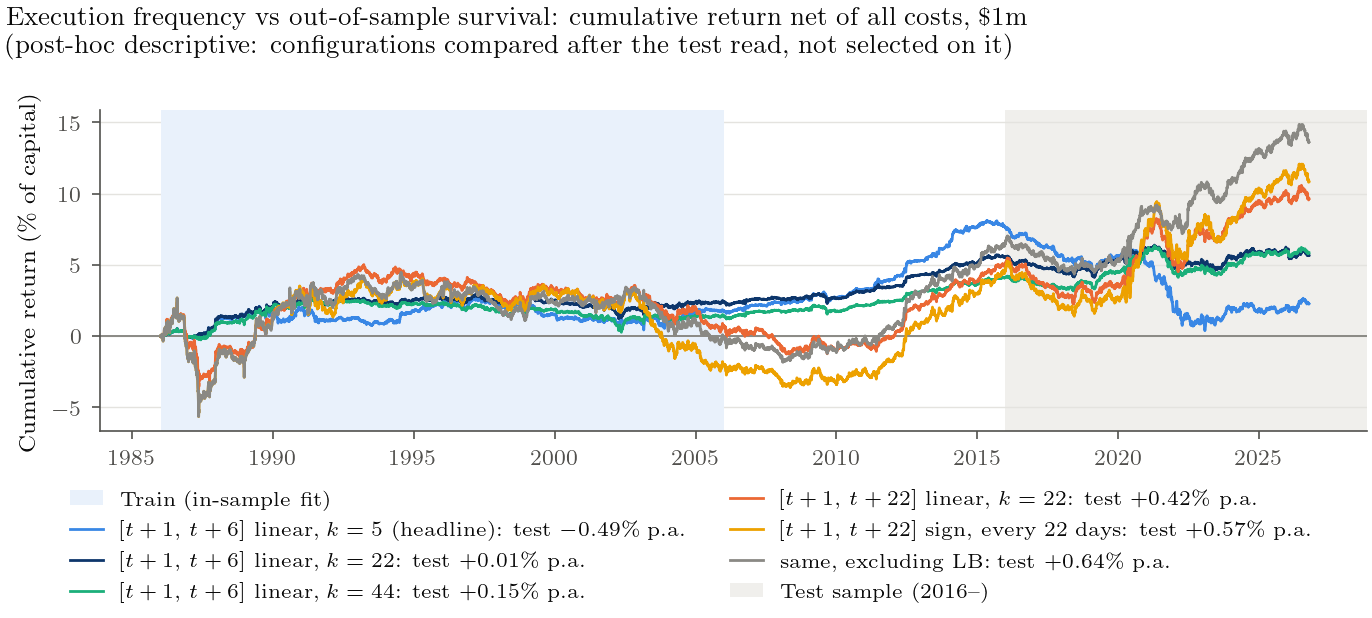

In [48]:
CFG_LABELS = {
    "fwd_1_6|linear|k=5": r"$[t+1,\,t+6]$ linear, $k=5$ (headline)",
    "fwd_1_6|linear|k=22": r"$[t+1,\,t+6]$ linear, $k=22$",
    "fwd_1_6|linear|k=44": r"$[t+1,\,t+6]$ linear, $k=44$",
    "fwd_1_22|linear|k=22": r"$[t+1,\,t+22]$ linear, $k=22$",
    "fwd_1_22|sign|every=22": r"$[t+1,\,t+22]$ sign, every 22 days",
    "fwd_1_22|sign|every=22|exLB": r"same, excluding LB",
}
fig = AF.nav_configs(desc_daily, CFG_LABELS)
ps.save(fig, "alpha_nav_configs");

**读图（事后）。** 长 horizon 预测 + 低频执行在 test 上扣完全部成本**仍为正**：`[t+1, t+22]` sign、每 22 天调仓 test net +0.57%/年（Sharpe 0.45，剔除 LB 0.58），`[t+1, t+22]` linear、k=22 为 +0.42%（0.41）；而 validation 上最好的短 horizon 头条在 test 上是 −0.49%（−0.61）。validation 的排名恰好反过来（长 horizon 配置 validation 净 Sharpe 只有 0.65–0.79）。

含义：按 validation Sharpe 选“最优”配置会偏向更短、更依赖信号新鲜度的执行；长 horizon 的信息（主要是 A / B 的 carry 类溢价）更稳健、换手更低。这是**看过 test 才发现的**，只能作为下一步 walk-forward 的预注册假设，不能当成样本外证据。

## 8. 结论

**信息层面，融合是成功的。** 12 个因子里，A（carry，方向与原始 A 相反）和 C（短期反转）在所有 horizon 都通过筛选，B 只在 10 天以上通过，E 只在 2–5 天勉强通过，D 在日频上一个都没过。合成之后，validation 的平均 IC 在 `[t+1, t+6]` 上是 0.068，比任何单因子都高；到了 test 期，5 天、10 天、22 天的 IC 仍然显著为正，22 天甚至升到 0.14。线性模型（OLS / Ridge / Lasso）在 paired bootstrap 里稳定地不输于 RF 和 XGBoost，XGBoost 在每个 horizon 上都没有赢过任何一个模型。Look-ahead 检验通过（预测推迟 1 天，IC 只从 0.068 降到 0.065）。

**IC 随 horizon 上升是噪声平均掉了，不是信息变多。** 原始 IC 在约 42 天到顶后下降；年化 IC（× √(252/h)）从 1 天起单调衰减。长 horizon 的好处在交易：同样的信息，换手低得多。

**变现层面，预先登记的头条没有通过 test。** validation 选出的 `[t+1, t+6]`、linear、\$1m 在 2006–2015 净 Sharpe 1.34，2016–2026 gross −0.21、net −0.61；截面对照同样为负。两个原因叠加：一个尾部品种（木材 LB，2021–2022 极端波动，test 中每年拖累 42bp gross，剔除后 gross 转正），以及 5 天 horizon 的高换手（剔除 LB 后 net 仍约 0）。validation 上选的低频版本（每 10 天调仓）也没有救回来。

**事后发现：长 horizon + 低频执行在 test 上活下来了。** `[t+1, t+22]` 预测每 22 天调仓，test net +0.57%/年（Sharpe 0.45）。但这在 validation 上不是最优，是读过 test 后才比较的，只能当作下一步的假设。

**规模与量级。** 成本主要是 half-spread 和 fee，impact 在 \$3m 以上才明显；\$100k 用整手几乎下不了单。即使最好的情况，年化收益也只有资本的 0.5% 左右（波动约 1%）：Sharpe 有意义，绝对收益需要杠杆。

## 9. 下一步（需要新的 decision，test 已经用过）

- 预注册“长 horizon（≥ 22 天）预测 + 月度调仓”为主配置，用 walk-forward（滚动 / 扩展窗口重拟合）评估，而不是再看一次 2016–2026。
- 仓位按 √dollar ADV（`scheme="liquidity"`）或按 spread 波动做风险预算，压低 LB 这类品种。
- 用 rolled 收益（而非 fixed-pair）作为长 horizon 的拟合目标，避免到期造成的样本选择。